# Lab01: Modeling, optimizer và hyperparameter tuning
Một luồng hiện hành. Chọn MODE=view để đọc artifact, MODE=train để chạy mới. Mọi kết quả chạy mới được lưu riêng; không ghi đè lịch sử.

## Bảng Lộ Trình Triển Khai Thực Tế (Pipeline Execution Roadmap)

| Bước | Giai đoạn (Phase) | Nội dung chi tiết (Core Description) | Module triển khai / Hàm thực thi | Sản phẩm đầu ra (Output / Artifact) |
| :---: | :--- | :--- | :--- | :--- |
| **1** | **Setup & Data Contract** | Cell setup tìm source; đọc registry và chọn view/train. Khi train, nạp prepared.npz được chọn; cùng split/seed, CPU hoặc CUDA. | [src/workflow.py](../src/workflow.py): `load_workflow_config`, `model_stage`, `saved_run`<br>[src/training/comparison.py](../src/training/comparison.py): `loaders`<br>[src/utils/helpers.py](../src/utils/helpers.py): `DEVICE` | `CONFIG`, `MODE`; mỗi run train lưu `config.json` có `data_sha256`, `environment_snapshot.json` |
| **2** | **Model & Sanity Overfit** | Trong mỗi `run_model`, khởi tạo SmallMLP 784-128-10, MainMLP 784-256-128-10 hoặc MainMLP_FE 794-256-128-10; sanity rồi reset model/seed/loaders. | [src/training/comparison.py](../src/training/comparison.py): `run_model`<br>[src/models/mlp.py](../src/models/mlp.py): `FashionMLP`<br>[src/training/trainer.py](../src/training/trainer.py): `sanity_overfit_check` | Mỗi model run: `sanity.json`, kiến trúc trong `config.json` |
| **3** | **Training** | `model_stage` gọi `run_model` khi train; Adam theo cấu hình mặc định và CosineAnnealingLR, lưu history mỗi epoch, chọn best bằng validation. | [src/workflow.py](../src/workflow.py): `model_stage`<br>[src/training/comparison.py](../src/training/comparison.py): `run_model`<br>[src/training/trainer.py](../src/training/trainer.py): `Trainer.fit`<br>[src/utils/plots.py](../src/utils/plots.py): `plot_loss_and_acc_curves` | Mỗi model run: `best.pt`, `history.json`, `history.csv`, `learning_curves.png` |
| **4** | **Test Evaluation** | Trong `run_model`, tải best checkpoint và đánh giá test; lưu xác suất, nhãn, metric và class report. | [src/training/comparison.py](../src/training/comparison.py): `run_model`<br>[src/utils/helpers.py](../src/utils/helpers.py): `load_checkpoint` | `test_predictions.npz`, `metrics.json`, `classification_report.json`, `classification_report.csv`, `grid_pixels.npy` |
| **5** | **Model Comparison** | `comparison_stage` đọc run đã chọn hoặc dựng so sánh từ ba model run; Accuracy/Macro F1, validation curves, chi phí, cùng 16 ảnh. Confusion matrix ghi số mẫu từng ô; màu chuẩn hóa theo hàng. | [src/workflow.py](../src/workflow.py): `comparison_stage`<br>[src/utils/comparison_plots.py](../src/utils/comparison_plots.py): `build_comparison`<br>[src/utils/plots.py](../src/utils/plots.py): `draw_confusion_counts` | Comparison run: `comparison.csv`, `test_scores.png`, `validation_comparison.png`, `cost.png`, `confusion_comparison.png`, `*_confusion_counts.csv`, `*_confusion_normalized.csv`, `*_prediction_grid.png`, `f1_by_class.csv` |
| **6** | **ROC & Precision–Recall OvR** | Cũng trong `build_comparison`: mỗi model một ảnh hai panel ROC/PR, mỗi panel 10 đường one-vs-rest; lưu tọa độ và điểm số. | [src/utils/comparison_plots.py](../src/utils/comparison_plots.py): `build_comparison` | Comparison run: `*_ovr_curves.png` (3 ảnh), `*_roc_*.csv`, `*_pr_*.csv`, `ovr_scores_by_class.csv` |
| **7** | **Fixed-LR Optimizers** | `optimizer_stage(..., phase="fixed")` gọi `run_fixed_lr` khi train: MainMLP pixel, SGD/RMSprop/Adam cùng LR=0.001; chỉ validation. | [src/workflow.py](../src/workflow.py): `optimizer_stage`<br>[src/training/tuning.py](../src/training/tuning.py): `run_fixed_lr`, `train_candidate` | Fixed run: `summary.csv`, `fixed_lr_curves.png`, `candidates/*/history.csv`, `candidates/*/best.pt` |
| **8** | **Hyperparameter Search** | `optimizer_stage(..., phase="tuning")` gọi ba study độc lập; mặc định 10 trial/optimizer, tune LR/weight decay/momentum SGD, MedianPruner. Run đang chọn có 10 startup trials nên chưa vào pha TPE thích nghi. | [src/workflow.py](../src/workflow.py): `optimizer_stage`<br>[src/training/tuning.py](../src/training/tuning.py): `run_tuning`, `train_candidate`, `plot_best_optimizer_histories` | Tuning run: `studies.sqlite3`, `*_trials.csv`, `all_trials.csv`, `best_configs.json`, `best_configs.csv`, `tuning_progress.png`, `trials/*`.<br>Run dựng hình sau search: `best_optimizer_learning_curves.png`, `best_optimizer_history.csv`, `best_parameters.csv` |
| **9** | **Refit & Final Evaluation** | Hai lời gọi `optimizer_stage`: `final` refit best trong study, sau đó `optimizer_results` tổng hợp fixed/tuned và test. Không mặc định tuning thắng baseline. | [src/workflow.py](../src/workflow.py): `optimizer_stage`<br>[src/training/tuning.py](../src/training/tuning.py): `refit_winner`, `summarize_optimizer_runs`<br>[src/utils/plots.py](../src/utils/plots.py): `draw_confusion_counts` | Refit model run: `learning_curves.png`, `history.csv`.<br>Refit wrapper run: `refit_run.json` trỏ tới model run chứa checkpoint/test metrics.<br>Results run: `fixed_vs_tuned.csv`, `fixed_vs_tuned.png`, `final_metrics.json`, `final_ovr_curves.png`, `final_confusion_matrix.png`, `final_confusion_counts.csv` |
| **10** | **Artifact Review & Tracking** | `show_tables`/`show_images` đọc artifact trong chính các cell trên. Run mới được `Run` ghi log/trạng thái/checksum; view không tự tạo run hay lưu notebook. | [src/workflow.py](../src/workflow.py): `show_tables`, `show_images`<br>[src/utils/runs.py](../src/utils/runs.py): `Run` | Mỗi run mới: `console.log`, `status.json`, `manifest.json`.<br>Notebook lưu output khi lưu file sau thực thi |

| **11** | **Save / Load the Model** | Lưu checkpoint refit, dựng instance mới, load state_dict và kiểm tra xác suất trước/sau trên tối đa 16 ảnh test. Cell luôn thực hiện thật, kể cả MODE=view. | [src/inference.py](../src/inference.py): `save_load_model`, `load_trained_run`<br>[src/utils/helpers.py](../src/utils/helpers.py): `save_checkpoint`, `load_checkpoint` | Save/load run: `best.pt`, `config.json`, `roundtrip.json`, `roundtrip_predictions.npz`, `model_architecture.txt`, `test_metrics.json`, `test_predictions.npz`, `loaded_model_test_samples.csv/png`, log/status/manifest |

**Cách đọc roadmap:** đây là luồng xử lý bên trong các hàm; một cell có thể thực hiện nhiều bước. Module bên dưới là file Python thật và có liên kết tương đối để mở từ notebook. `MODE="train"` tạo run mới cùng log, status và manifest; `MODE="view"` đọc các run huấn luyện được chọn trong `config/workflow.json`, không train lại. Cell dựng hình ba optimizer sau search và bước 11 luôn tạo artifact mới; không huấn luyện lại. Các đường dẫn artifact là tương đối trong run của từng giai đoạn, không phải tất cả nằm trong một run.


In [23]:
from pathlib import Path
import sys
candidates = [Path.cwd(), *Path.cwd().parents]
LAB = next((p for p in candidates if (p / 'src/models/mlp.py').is_file()), None)
if LAB is None:
    LAB = next((p / 'labs/lab01' for p in candidates if (p / 'labs/lab01/src/models/mlp.py').is_file()), None)
if LAB is None:
    raise RuntimeError('Set working directory to the repository or lab01 folder; on Kaggle mount/copy the lab source first.')
sys.path.insert(0, str(LAB))
from src.utils.helpers import OUTPUTS_DIR
from IPython.display import display, Image


## 1. Cấu hình và chế độ
Cấu hình và run được chọn tường minh trong config/workflow.json. Không tự lấy run mới nhất. Trên Kaggle, copy artifact và cấu hình đường dẫn phù hợp trước khi dùng view.

In [24]:
from src.workflow import (load_workflow_config, model_stage, comparison_stage,
                          optimizer_stage, show_tables, show_images)
CONFIG = load_workflow_config()
MODE = 'train'  # Change to 'train' to create new runs.
print('Mode:', MODE, '| seed:', CONFIG['seed'], '| epochs:', CONFIG['epochs'])
import torch
torch.set_num_threads(CONFIG["torch_threads"])

Mode: train | seed: 42 | epochs: 10


## SmallMLP
Đọc run đã chọn hoặc sanity/reset/train theo cấu hình chung; learning curves hiển thị một lần.

Run: C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T164309Z_SmallMLP_db712c5c
Training device: cpu; epochs: 10
Epoch 01/10 | Train loss: 0.5022 | Val accuracy: 86.92%
Epoch 02/10 | Train loss: 0.3712 | Val accuracy: 87.45%
Epoch 03/10 | Train loss: 0.3326 | Val accuracy: 88.63%
Epoch 04/10 | Train loss: 0.3049 | Val accuracy: 88.73%
Epoch 05/10 | Train loss: 0.2814 | Val accuracy: 88.93%
Epoch 06/10 | Train loss: 0.2640 | Val accuracy: 89.07%
Epoch 07/10 | Train loss: 0.2476 | Val accuracy: 89.87%
Epoch 08/10 | Train loss: 0.2346 | Val accuracy: 89.95%
Epoch 09/10 | Train loss: 0.2256 | Val accuracy: 90.07%
Epoch 10/10 | Train loss: 0.2202 | Val accuracy: 90.00%
{'name': 'SmallMLP', 'seed': 42, 'accuracy': 0.8852, 'macro_f1': 0.8849484207722373, 'precision': 0.8850570180861916, 'recall': 0.8852, 'loss': 0.321349173784256, 'train_seconds': 11.088937200000146, 'parameters': 101770, 'best_epoch': 9}


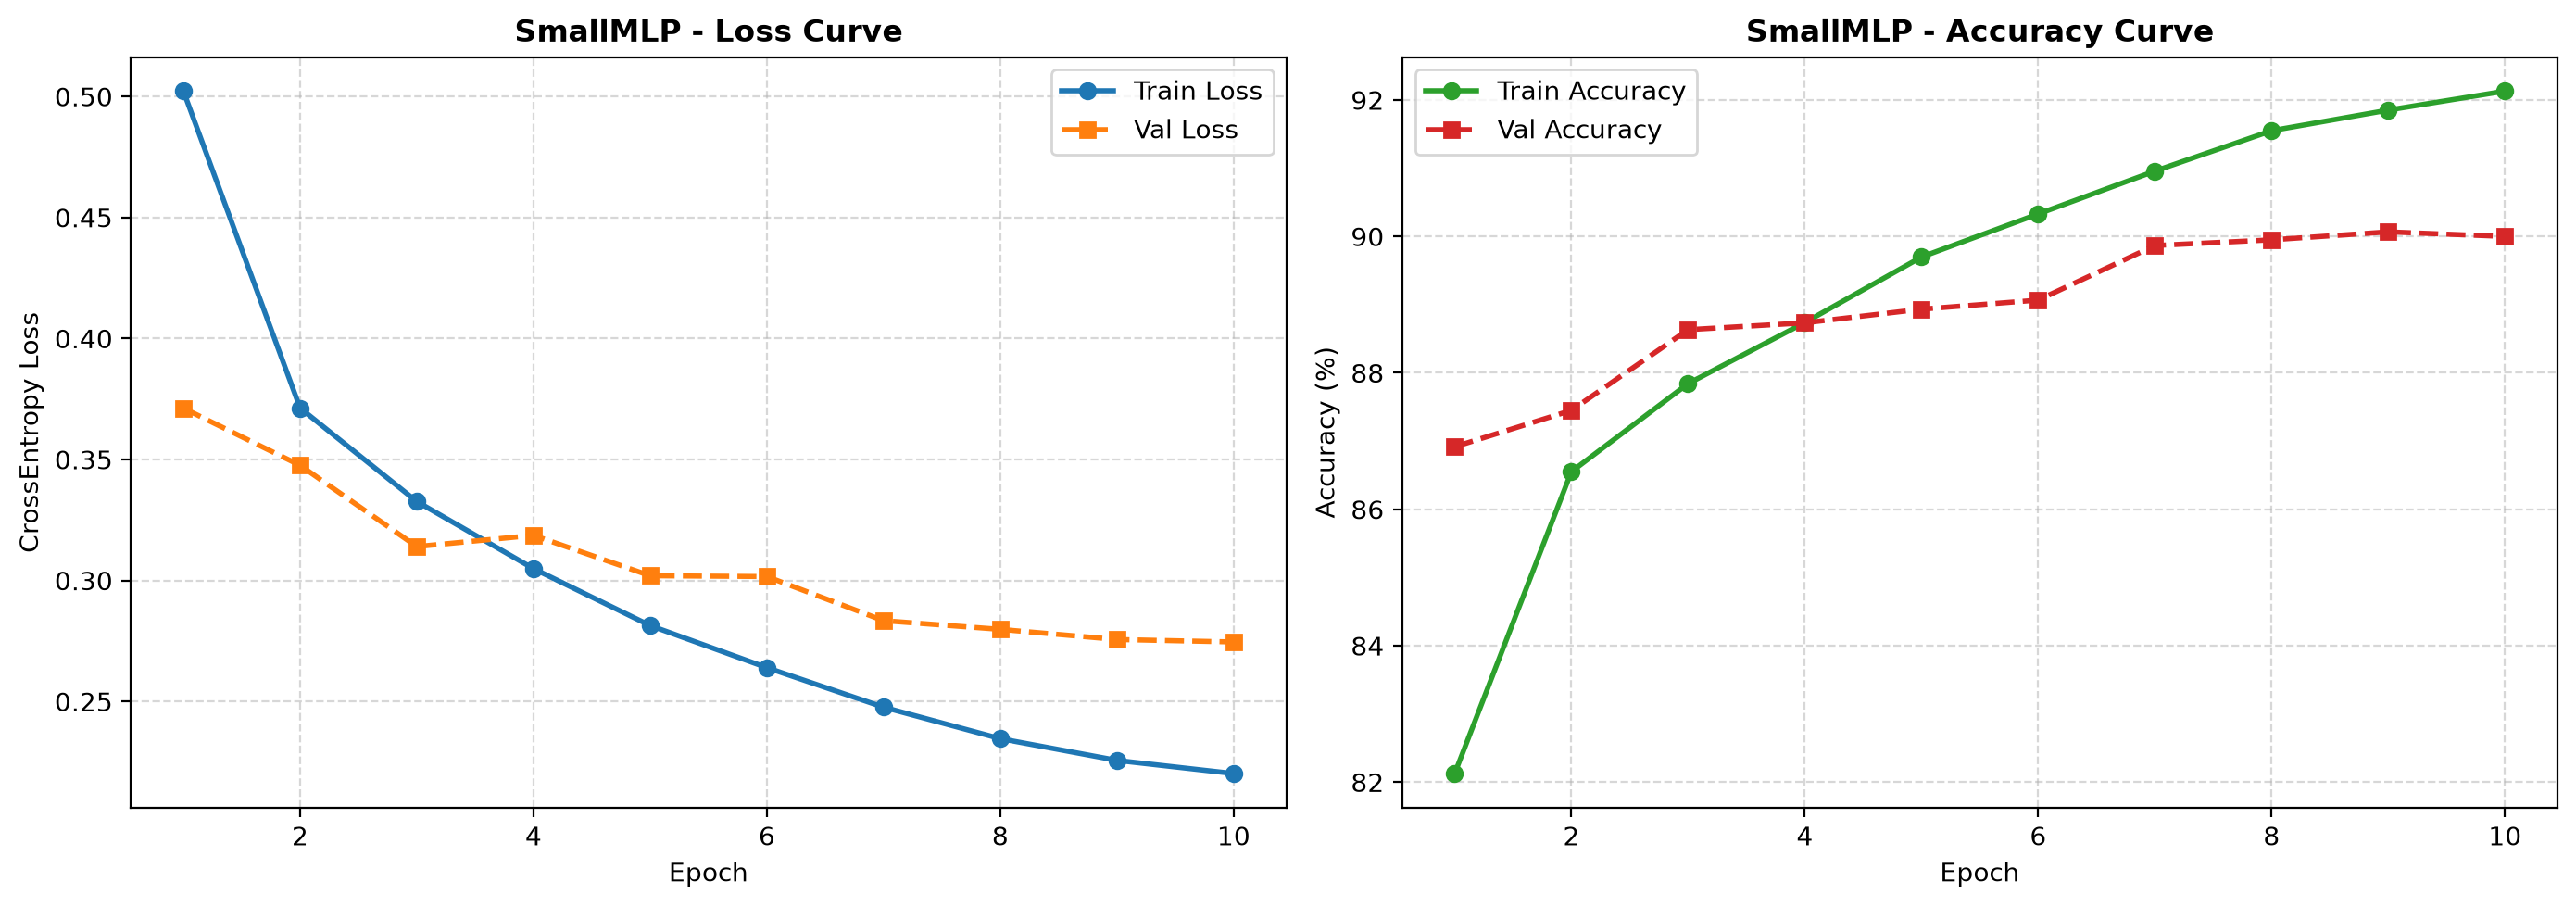

In [25]:
SmallMLP_RUN = model_stage(CONFIG, 'SmallMLP', MODE)
show_images(SmallMLP_RUN, ['learning_curves.png'])

## MainMLP
Đọc run đã chọn hoặc sanity/reset/train theo cấu hình chung; learning curves hiển thị một lần.

Run: C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T164326Z_MainMLP_daa28561
Training device: cpu; epochs: 10
Epoch 01/10 | Train loss: 0.4995 | Val accuracy: 86.67%
Epoch 02/10 | Train loss: 0.3563 | Val accuracy: 88.37%
Epoch 03/10 | Train loss: 0.3153 | Val accuracy: 89.02%
Epoch 04/10 | Train loss: 0.2858 | Val accuracy: 88.97%
Epoch 05/10 | Train loss: 0.2580 | Val accuracy: 89.67%
Epoch 06/10 | Train loss: 0.2368 | Val accuracy: 89.92%
Epoch 07/10 | Train loss: 0.2148 | Val accuracy: 90.25%
Epoch 08/10 | Train loss: 0.1962 | Val accuracy: 90.45%
Epoch 09/10 | Train loss: 0.1826 | Val accuracy: 90.72%
Epoch 10/10 | Train loss: 0.1744 | Val accuracy: 90.93%
{'name': 'MainMLP', 'seed': 42, 'accuracy': 0.8939, 'macro_f1': 0.8936648531124163, 'precision': 0.8936946787179636, 'recall': 0.8939, 'loss': 0.3096337914466858, 'train_seconds': 15.94197239999994, 'parameters': 235146, 'best_epoch': 10}


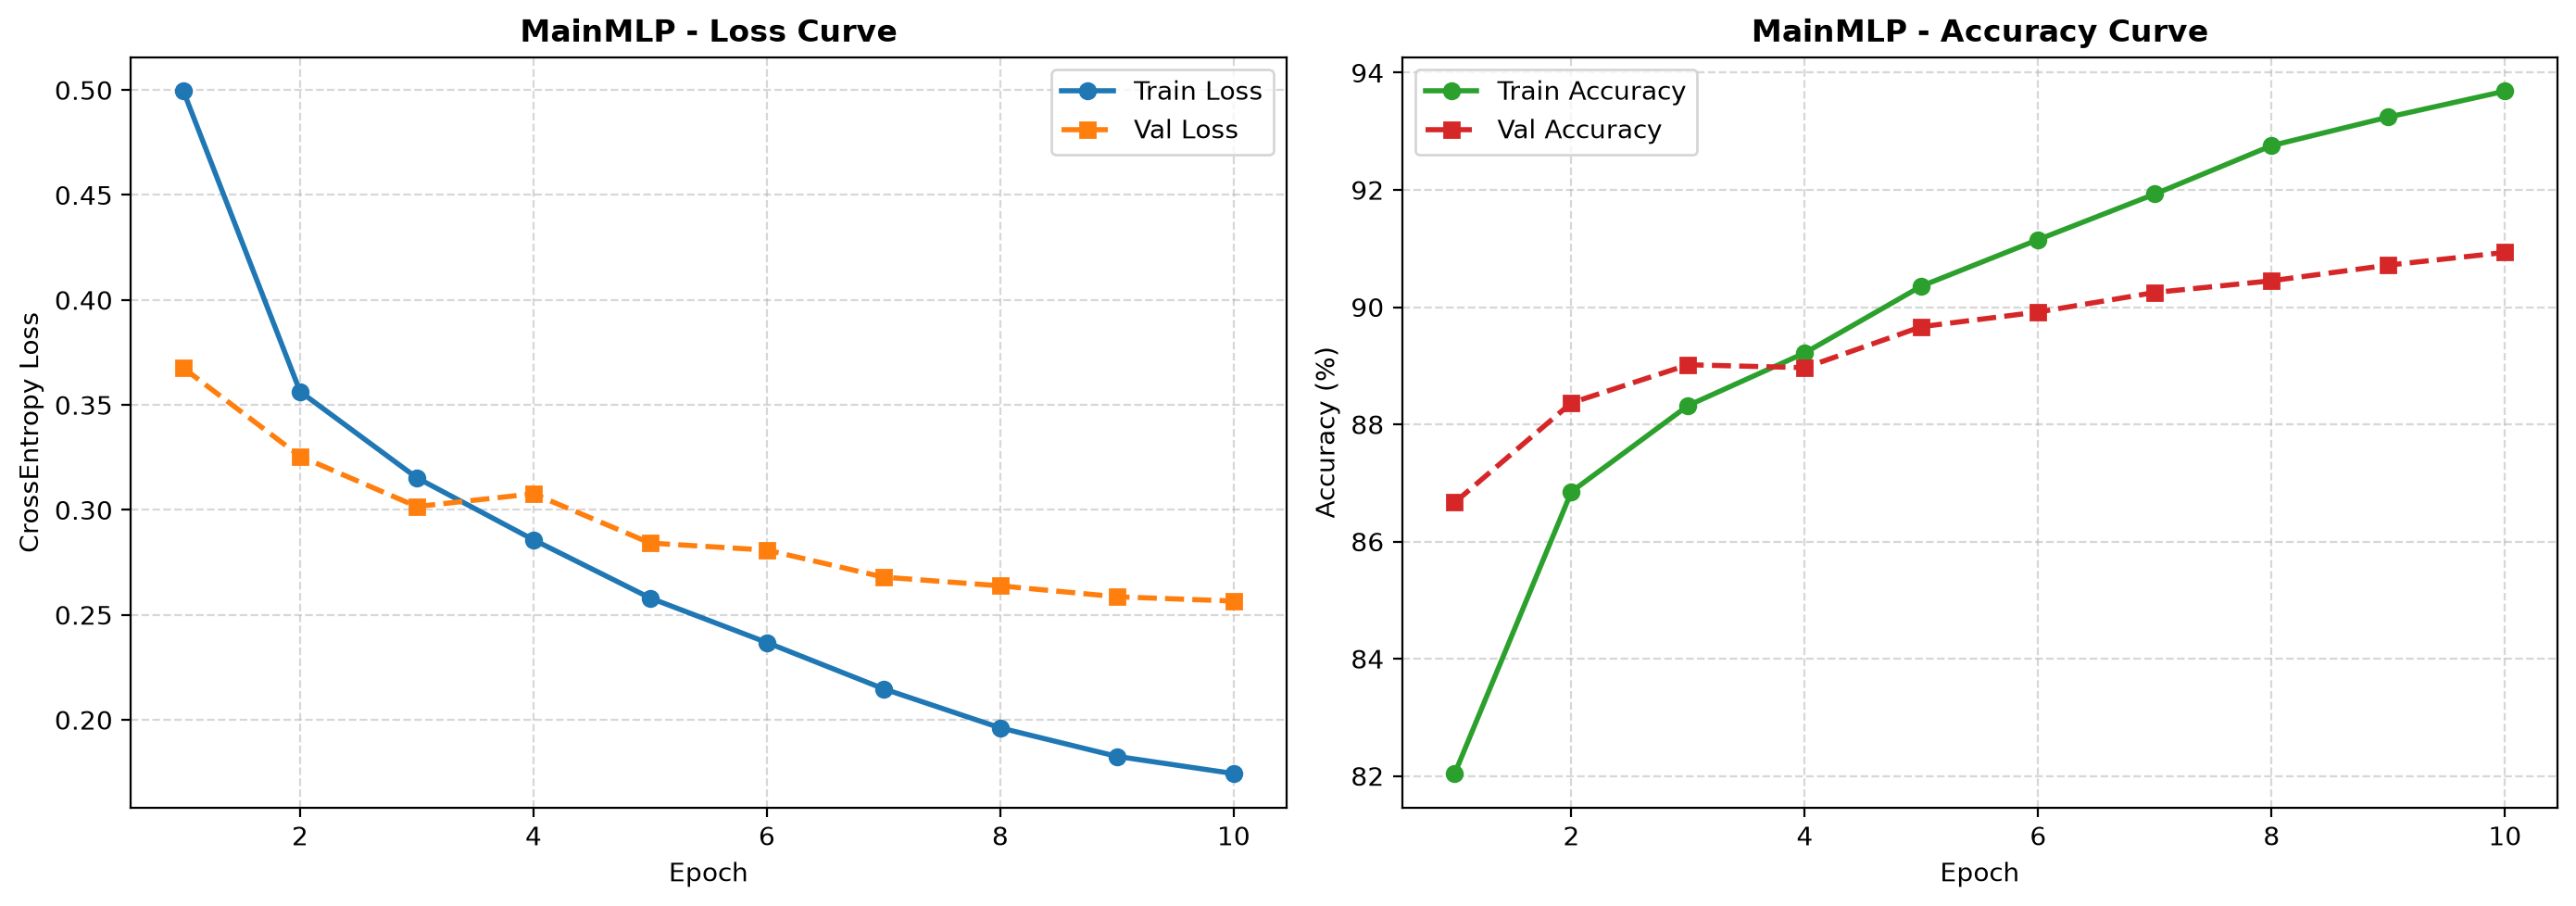

In [26]:
MainMLP_RUN = model_stage(CONFIG, 'MainMLP', MODE)
show_images(MainMLP_RUN, ['learning_curves.png'])

## MainMLP_FE
Đọc run đã chọn hoặc sanity/reset/train theo cấu hình chung; learning curves hiển thị một lần.

Run: C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T164346Z_MainMLP_FE_2abb35af
Training device: cpu; epochs: 10
Epoch 01/10 | Train loss: 0.4871 | Val accuracy: 87.05%
Epoch 02/10 | Train loss: 0.3463 | Val accuracy: 88.27%
Epoch 03/10 | Train loss: 0.3066 | Val accuracy: 89.18%
Epoch 04/10 | Train loss: 0.2759 | Val accuracy: 89.72%
Epoch 05/10 | Train loss: 0.2496 | Val accuracy: 89.75%
Epoch 06/10 | Train loss: 0.2282 | Val accuracy: 89.98%
Epoch 07/10 | Train loss: 0.2062 | Val accuracy: 90.48%
Epoch 08/10 | Train loss: 0.1890 | Val accuracy: 90.50%
Epoch 09/10 | Train loss: 0.1758 | Val accuracy: 90.82%
Epoch 10/10 | Train loss: 0.1676 | Val accuracy: 90.83%
{'name': 'MainMLP_FE', 'seed': 42, 'accuracy': 0.8957, 'macro_f1': 0.8953734255991115, 'precision': 0.8952774379332247, 'recall': 0.8956999999999999, 'loss': 0.3013155162334442, 'train_seconds': 15.996137799999815, 'parameters': 237706, 'best_epoch': 10}


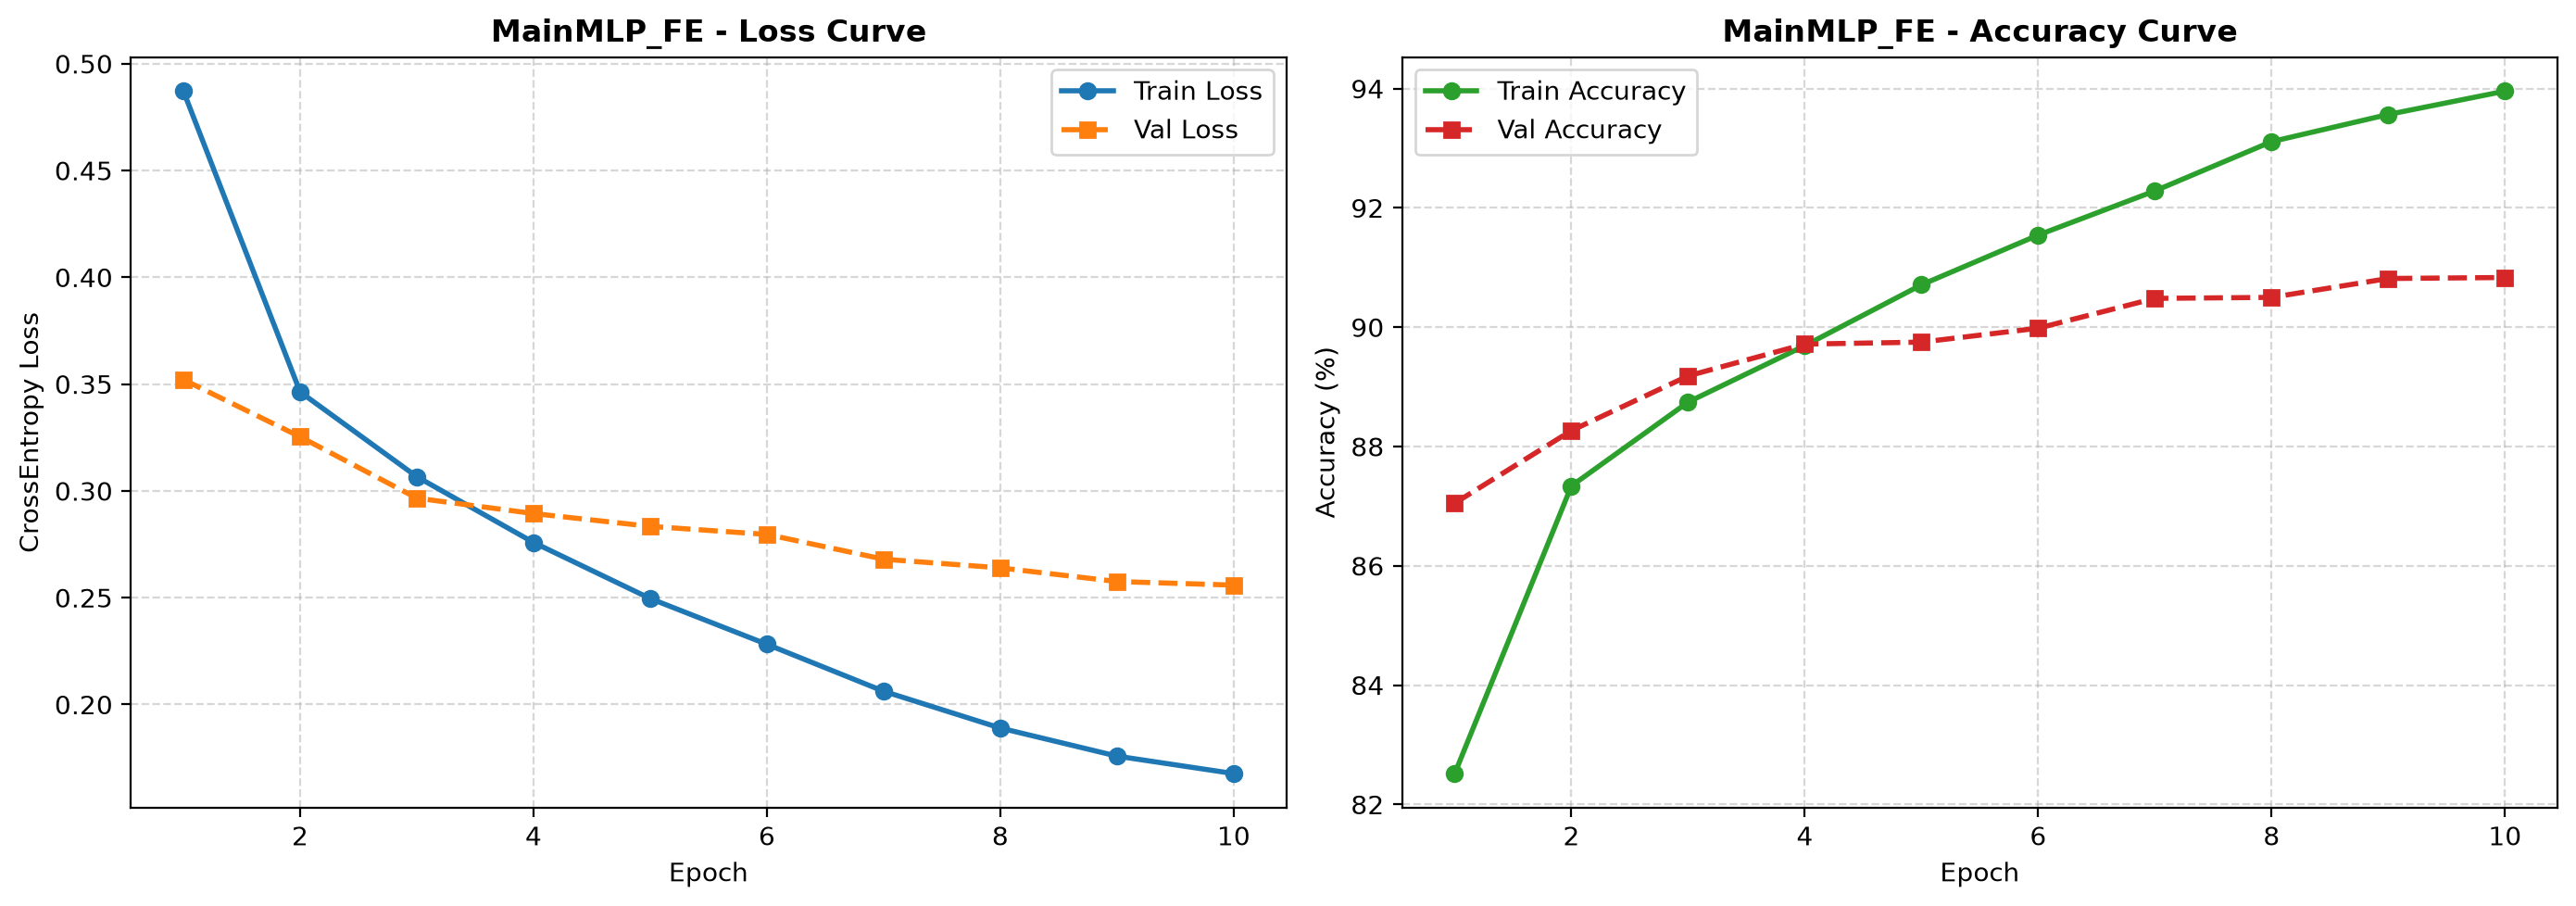

In [27]:
MainMLP_FE_RUN = model_stage(CONFIG, 'MainMLP_FE', MODE)
show_images(MainMLP_FE_RUN, ['learning_curves.png'])

## 2. So sánh ba model
Cùng split/điều kiện; so dung lượng Small/Main và tác động FE Main/Main_FE. Một ảnh ROC+PR OvR mỗi model, confusion matrices chung. Các hình chi phí/prediction grid và CSV vẫn có trong artifact.
Confusion matrix: số trong ô là số ảnh; màu và colorbar là tỷ lệ trong lớp thật (chuẩn hóa theo hàng). Cả ô bằng 0 cũng hiển thị số.


Run: C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T164405Z_comparison_e9a2b268
      name  seed  accuracy  macro_f1  precision  recall     loss  train_seconds  parameters  best_epoch
  SmallMLP    42    0.8852  0.884948   0.885057  0.8852 0.321349      11.088937      101770           9
   MainMLP    42    0.8939  0.893665   0.893695  0.8939 0.309634      15.941972      235146          10
MainMLP_FE    42    0.8957  0.895373   0.895277  0.8957 0.301316      15.996138      237706          10
comparison.csv


,name,seed,accuracy,macro_f1,precision,recall,loss,train_seconds,parameters,best_epoch
0,SmallMLP,42,0.8852,0.884948,0.885057,0.8852,0.321349,11.088937,101770,9
1,MainMLP,42,0.8939,0.893665,0.893695,0.8939,0.309634,15.941972,235146,10
2,MainMLP_FE,42,0.8957,0.895373,0.895277,0.8957,0.301316,15.996138,237706,10


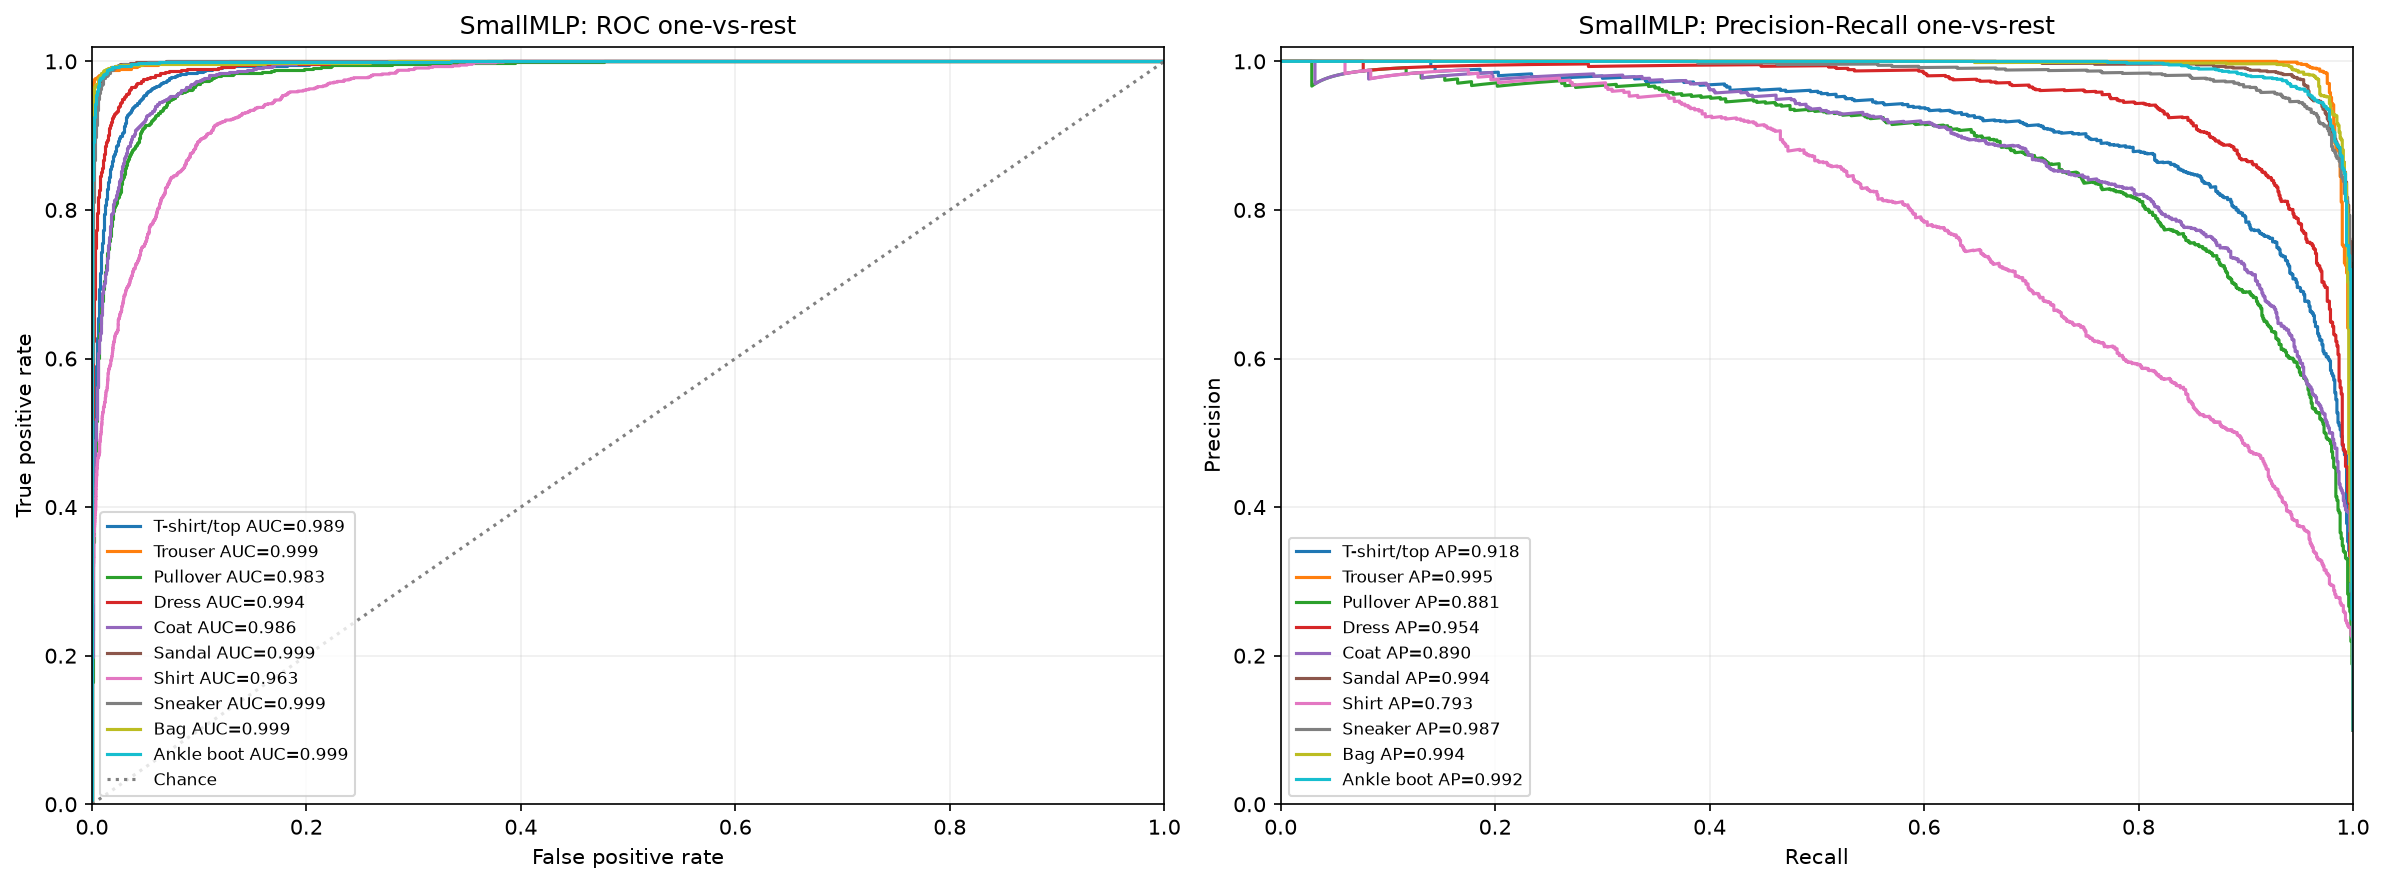

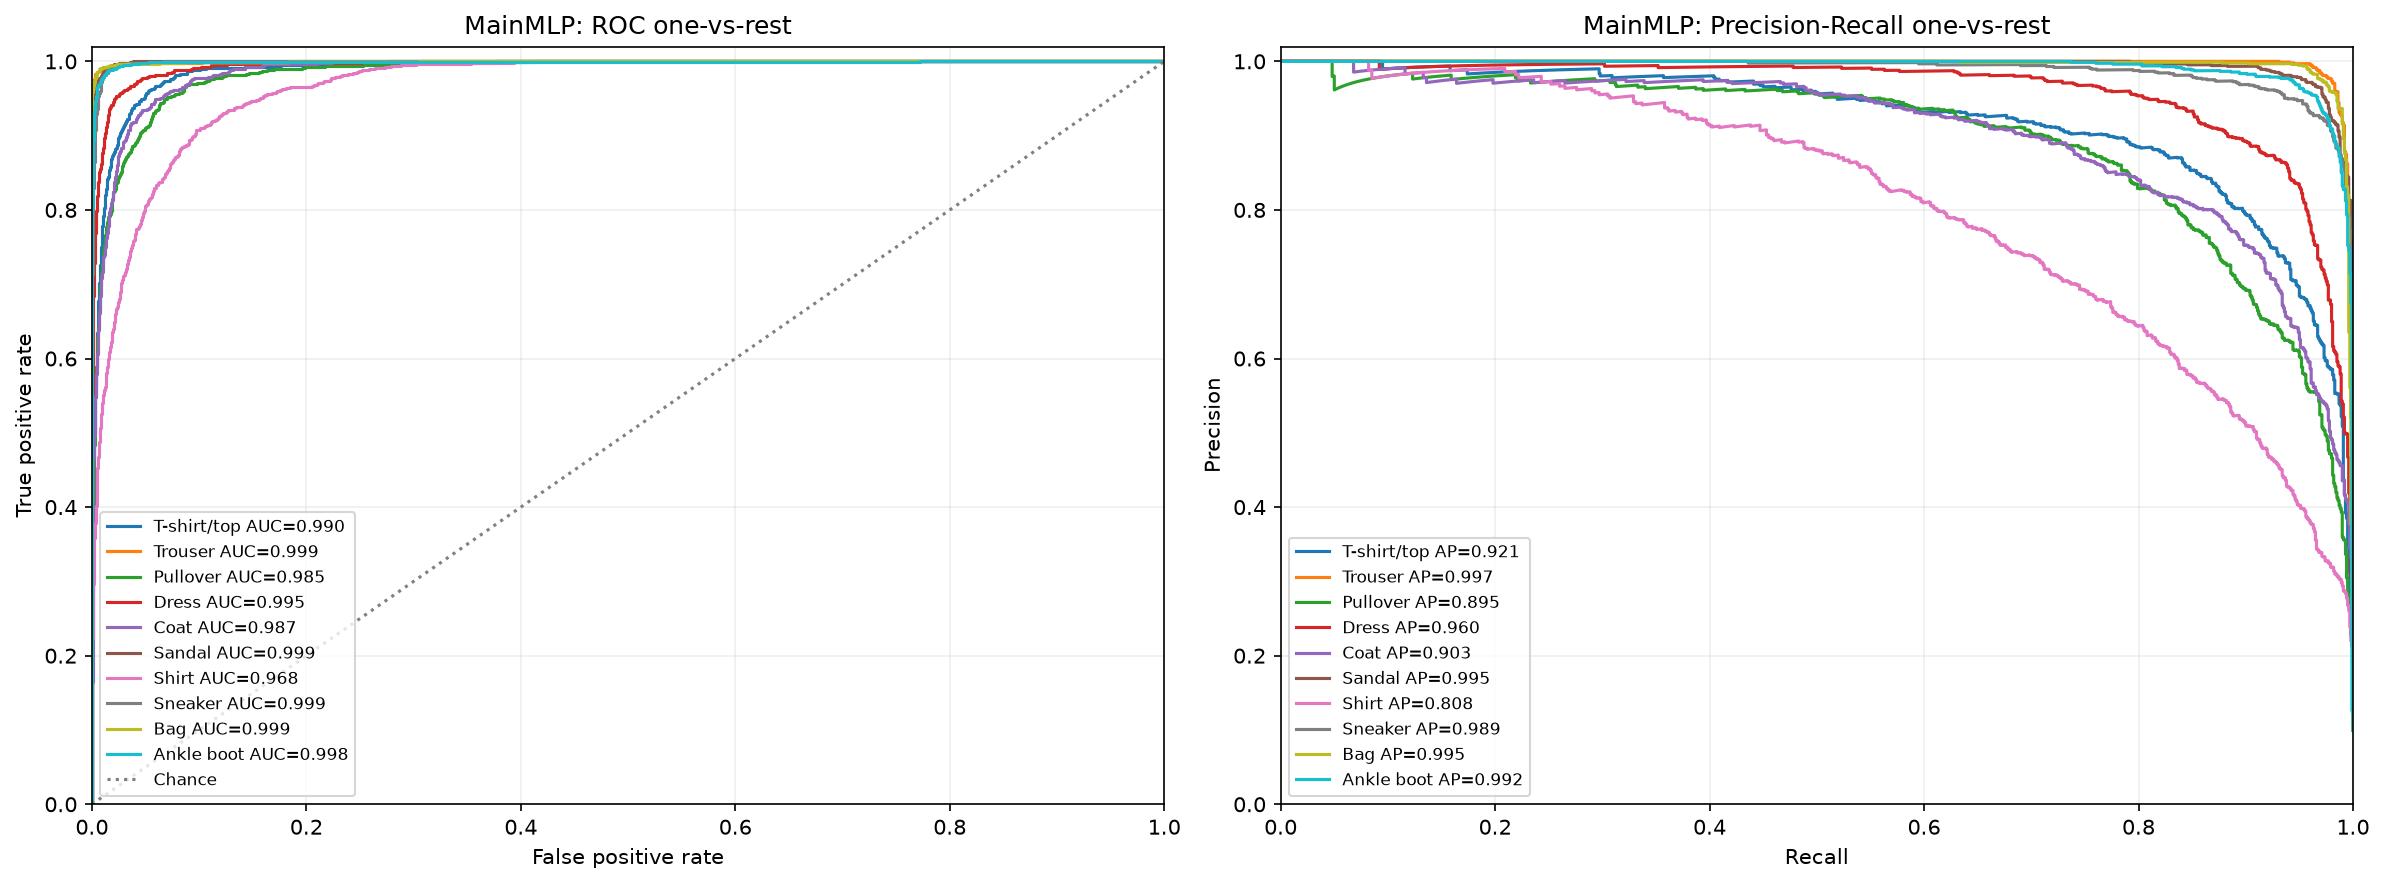

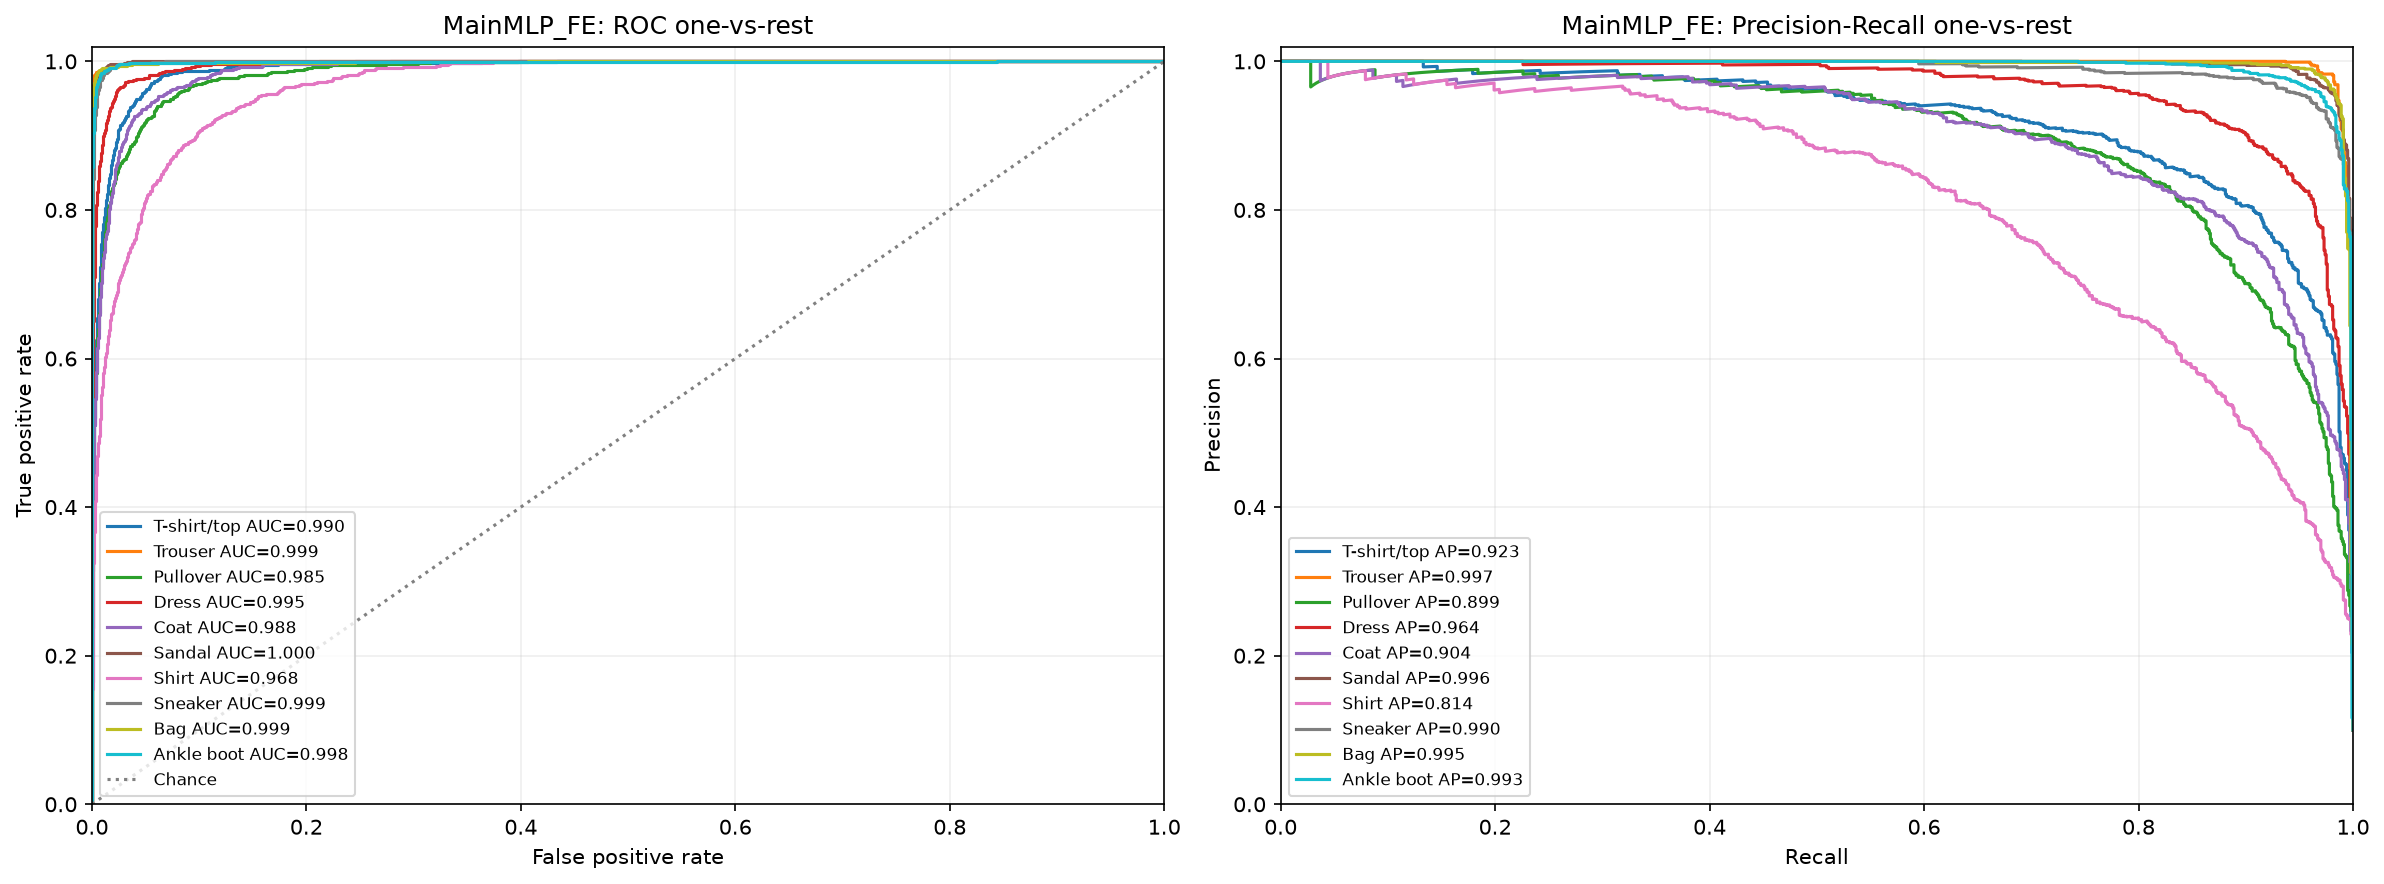

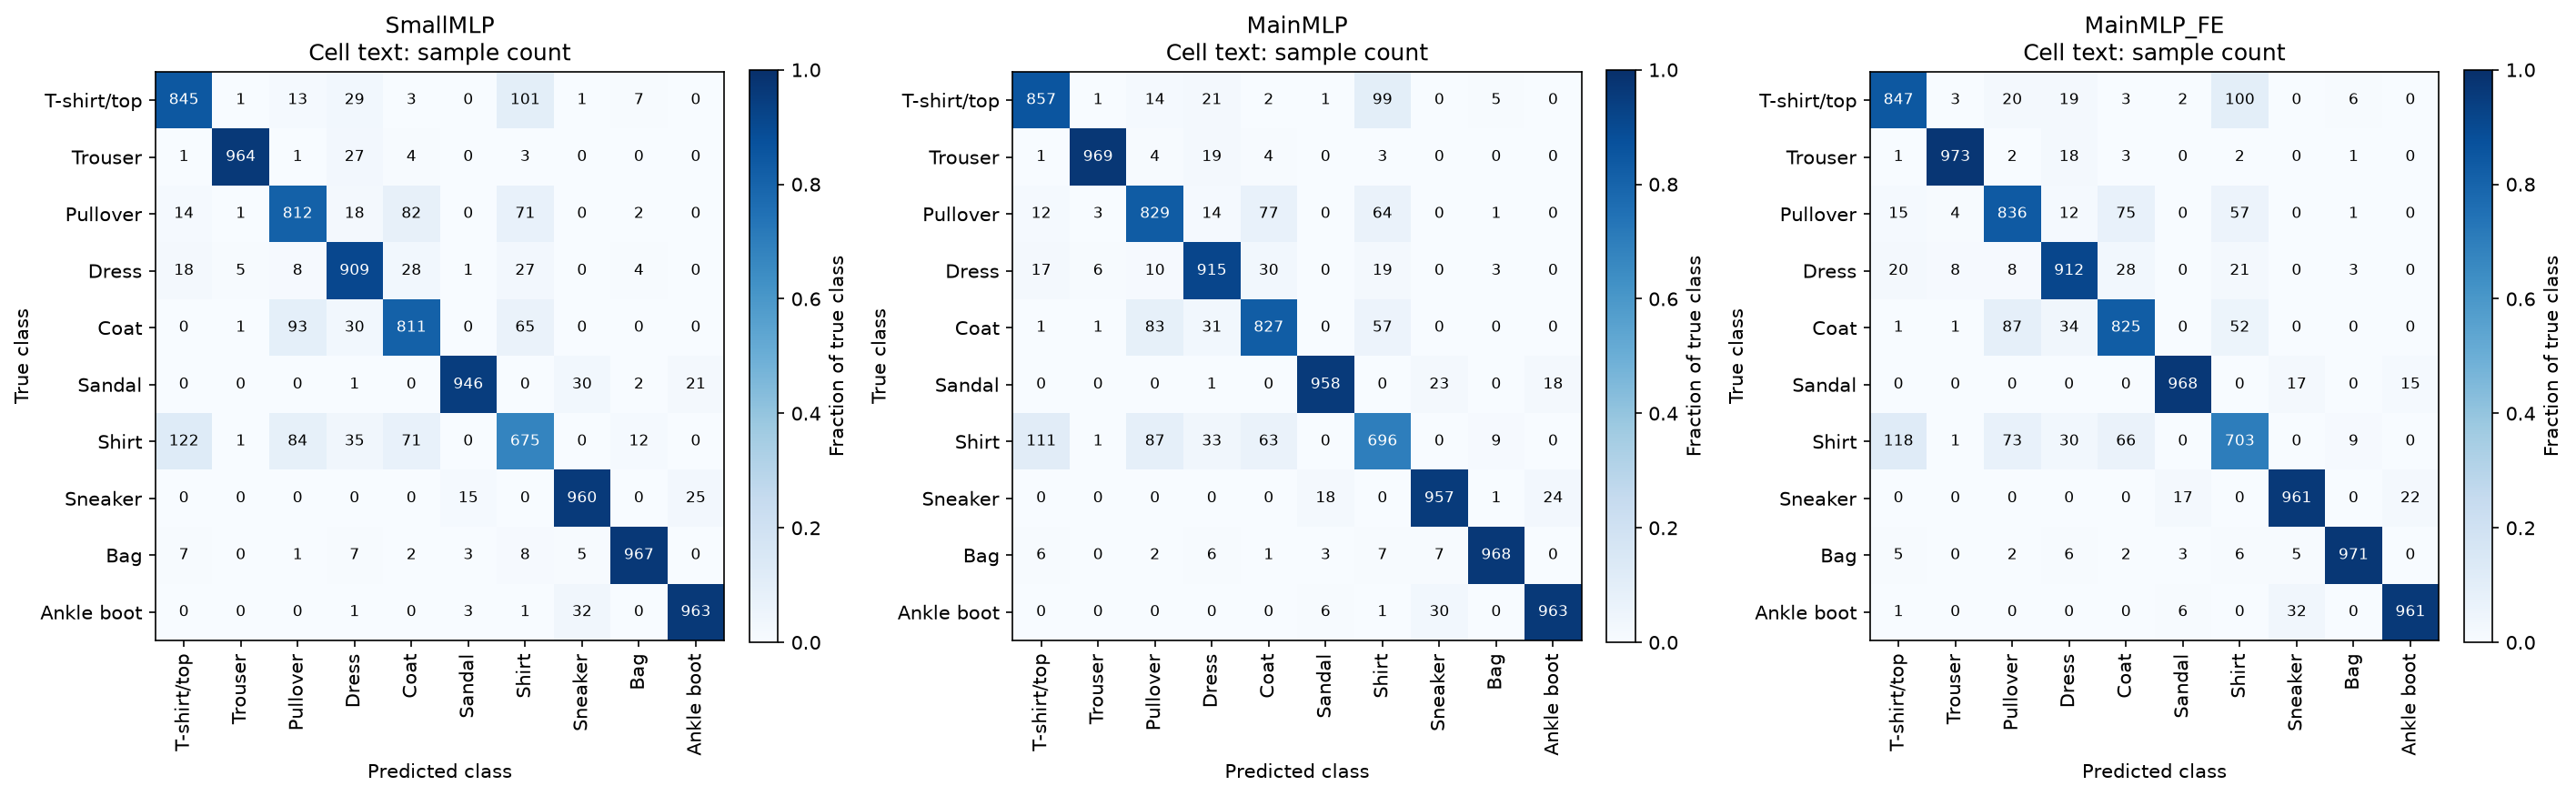

In [28]:
COMPARISON_RUN = comparison_stage(CONFIG, [SmallMLP_RUN, MainMLP_RUN, MainMLP_FE_RUN], MODE)
show_tables(COMPARISON_RUN, ['comparison.csv'])
show_images(COMPARISON_RUN, ['SmallMLP_ovr_curves.png', 'MainMLP_ovr_curves.png', 'MainMLP_FE_ovr_curves.png', 'confusion_comparison.png'])

## 3. Optimizer cùng LR
MainMLP pixel, SGD/RMSprop/Adam cùng LR=0.001, weight_decay=0; chỉ validation.

Run: C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T164415Z_optimizer_fixed_lr_fcbd836a
Run: C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T164415Z_optimizer_fixed_lr_fcbd836a\candidates\20261022T164415Z_SGD_813f4fa5
SGD epoch 1/10: val_acc=75.533, loss=0.7158
SGD epoch 2/10: val_acc=80.233, loss=0.5601
SGD epoch 3/10: val_acc=82.533, loss=0.5003
SGD epoch 4/10: val_acc=83.500, loss=0.4712
SGD epoch 5/10: val_acc=84.000, loss=0.4551
SGD epoch 6/10: val_acc=84.533, loss=0.4427
SGD epoch 7/10: val_acc=84.883, loss=0.4332
SGD epoch 8/10: val_acc=84.867, loss=0.4289
SGD epoch 9/10: val_acc=85.083, loss=0.4266
SGD epoch 10/10: val_acc=85.033, loss=0.4264
Run: C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T164415Z_optimizer_fixed_lr_fcbd836a\candidates\20261022T164430Z_RMSprop_1f8d0d17
RMSprop epoch 1/10: val_acc=85.267, loss=0.3951
RMSprop epoch 2/10: val_acc=87.583, loss=0.3331
RMSprop epoch 3/10: val_acc=87.967, loss=0.3321
RMSprop 

,optimizer,run_path,best_val_acc,best_epoch,seconds,epochs_completed
0,SGD,C:\Users\Win 11\Documents\Lab DL\labs\lab01\ou...,85.083333,9,13.477502,10
1,RMSprop,C:\Users\Win 11\Documents\Lab DL\labs\lab01\ou...,90.733333,10,14.221538,10
2,Adam,C:\Users\Win 11\Documents\Lab DL\labs\lab01\ou...,90.933333,10,15.286586,10


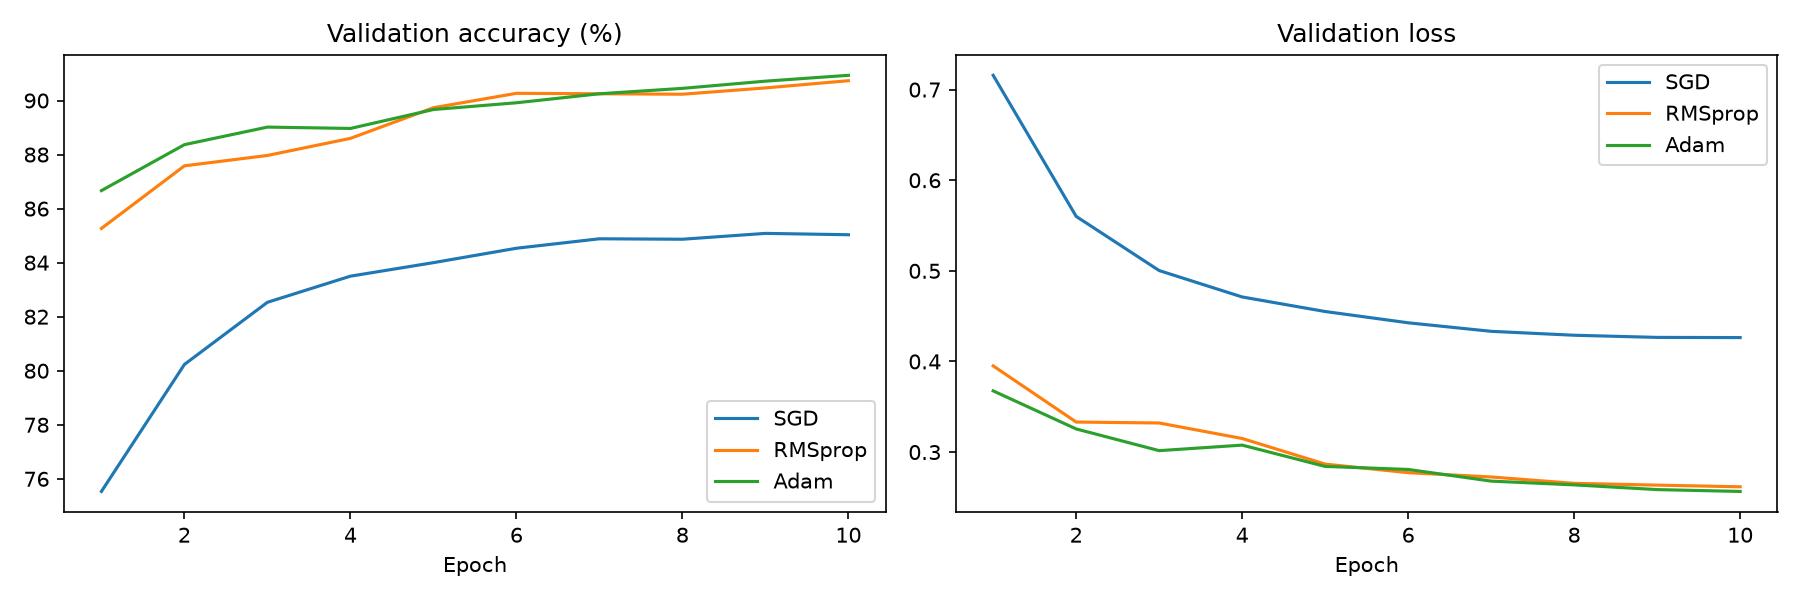

In [29]:
FIXED_RUN = optimizer_stage(CONFIG, 'fixed', MODE)
show_tables(FIXED_RUN, ['summary.csv'])
show_images(FIXED_RUN, ['fixed_lr_curves.png'])

## 4. Hyperparameter search
Optuna TPE + MedianPruner; ngân sách tối đa bằng nhau theo trial/epoch. Chọn config bằng validation. Đợt 10 trial có 10 startup trials nên chưa đi vào pha TPE thích nghi.

Run: C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T164502Z_optimizer_tuning_81d4b367


c:\Users\Win 11\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Run: C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T164502Z_optimizer_tuning_81d4b367\trials\SGD\20261022T164503Z_SGD_5a3fd167
SGD epoch 1/10: val_acc=84.267, loss=0.4518
SGD epoch 2/10: val_acc=84.800, loss=0.4162
SGD epoch 3/10: val_acc=87.283, loss=0.3718
SGD epoch 4/10: val_acc=87.350, loss=0.3709
SGD epoch 5/10: val_acc=87.733, loss=0.3582
SGD epoch 6/10: val_acc=87.283, loss=0.3578
SGD epoch 7/10: val_acc=88.133, loss=0.3466
SGD epoch 8/10: val_acc=87.967, loss=0.3447
SGD epoch 9/10: val_acc=88.900, loss=0.3385
SGD epoch 10/10: val_acc=88.683, loss=0.3385
SGD trial 0: COMPLETE; value=88.9; params={'lr': 0.005611516415334507, 'weight_decay': 0.005669849511478858, 'momentum': 0.9097990912717108}
Run: C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T164502Z_optimizer_tuning_81d4b367\trials\SGD\20261022T164518Z_SGD_2329fc2f
SGD epoch 1/10: val_acc=84.350, loss=0.4390
SGD epoch 2/10: val_acc=87.267, loss=0.3607
SGD epoch 3/10: val_acc=88.050, loss=0

,optimizer,best_val_acc,trial_number,run_path,lr,weight_decay,momentum,trials,completed,pruned,seconds
0,SGD,90.800000,3,C:\Users\Win 11\Documents\Lab DL\labs\lab01\ou...,0.026070,1.267426e-07,0.945486,10,5,5,100.573697
1,RMSprop,90.566667,4,C:\Users\Win 11\Documents\Lab DL\labs\lab01\ou...,0.001593,3.470267e-04,NaN,10,6,4,132.468404
2,Adam,90.850000,4,C:\Users\Win 11\Documents\Lab DL\labs\lab01\ou...,0.001593,3.470267e-04,NaN,10,5,5,133.978890


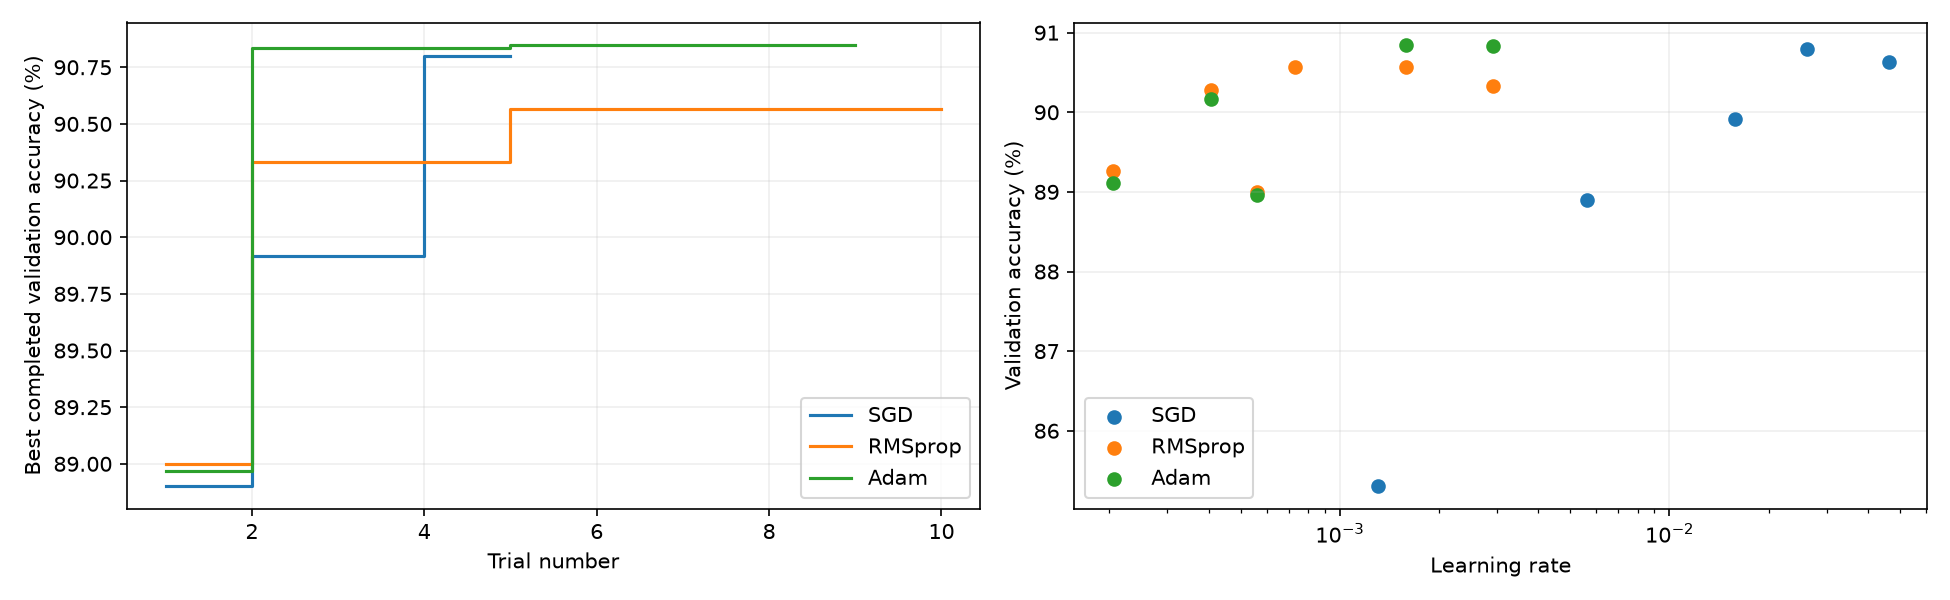

In [30]:
TUNING_RUN = optimizer_stage(CONFIG, 'tuning', MODE)
show_tables(TUNING_RUN, ['best_configs.csv'])
show_images(TUNING_RUN, ['tuning_progress.png'])

### Loss và accuracy sau search: đủ ba optimizer
Bốn panel lần lượt là train loss, validation loss, train accuracy và validation accuracy; **mỗi panel có ba đường SGD, RMSprop, Adam**. Mỗi optimizer dùng history của best completed trial đã chọn bằng validation với best parameters riêng. Đây là lịch sử trial tốt nhất, không giả định cả ba đã được refit mới. Bảng best parameters và history được lưu cùng hình trong run riêng.

Run: C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T165112Z_best_optimizer_learning_curves_9fce73dd
Saved train/validation loss and accuracy for SGD, RMSprop and Adam: C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T165112Z_best_optimizer_learning_curves_9fce73dd
best_parameters.csv


,optimizer,best_val_acc,trial_number,run_path,lr,weight_decay,momentum
0,SGD,90.800000,3,C:\Users\Win 11\Documents\Lab DL\labs\lab01\ou...,0.026070,1.267426e-07,0.945486
1,RMSprop,90.566667,4,C:\Users\Win 11\Documents\Lab DL\labs\lab01\ou...,0.001593,3.470267e-04,NaN
2,Adam,90.850000,4,C:\Users\Win 11\Documents\Lab DL\labs\lab01\ou...,0.001593,3.470267e-04,NaN


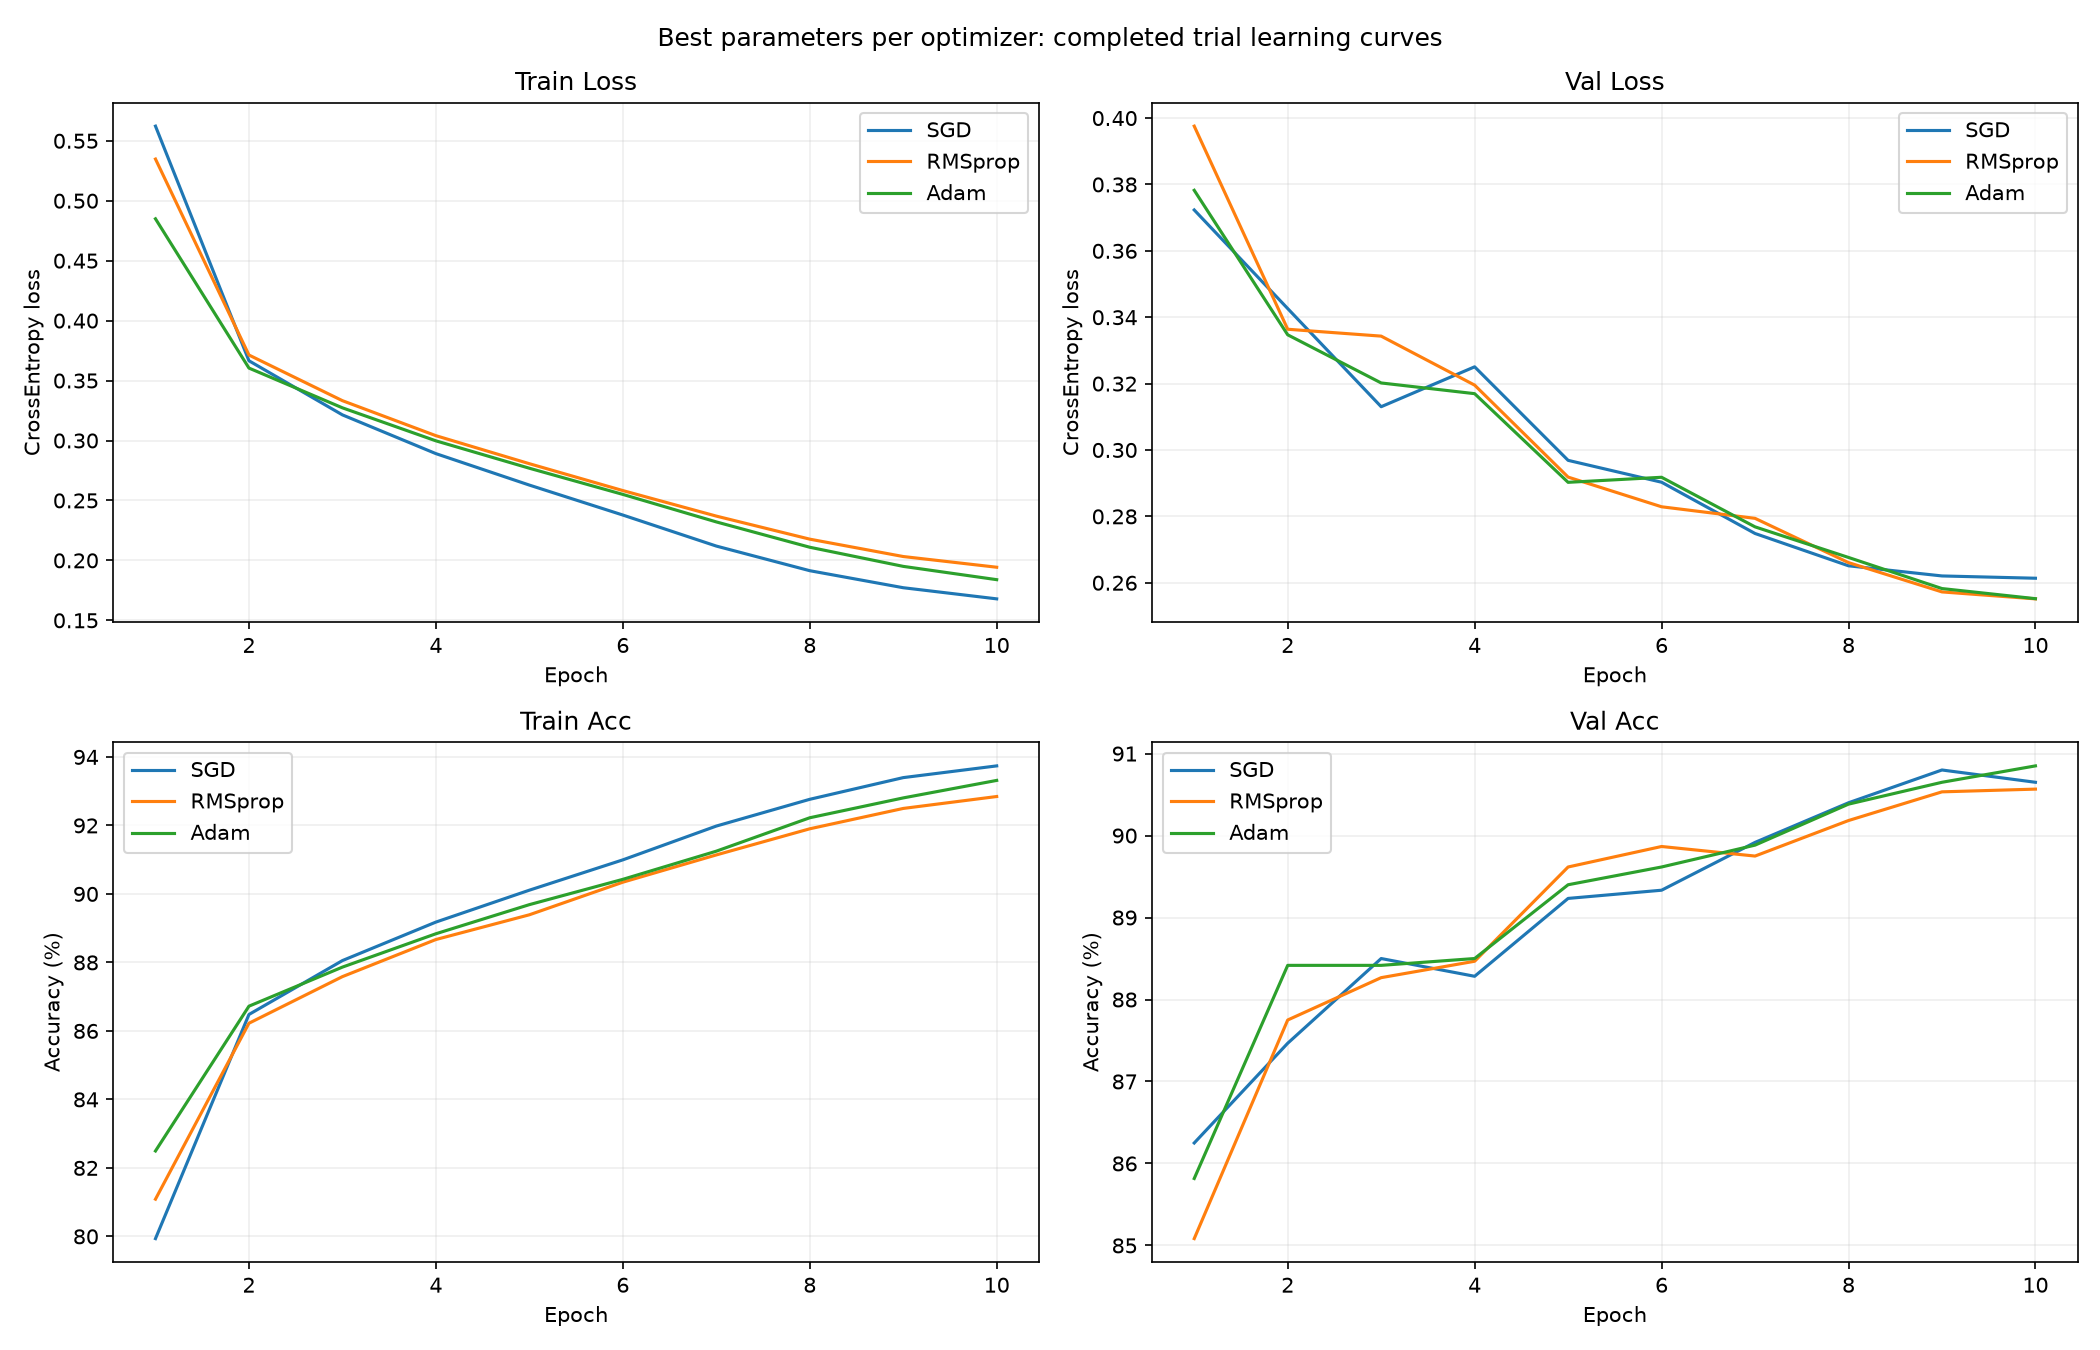

In [31]:
from src.training.tuning import plot_best_optimizer_histories
BEST_OPTIMIZER_CURVES_RUN = plot_best_optimizer_histories(TUNING_RUN)
show_tables(BEST_OPTIMIZER_CURVES_RUN, ['best_parameters.csv'])
show_images(BEST_OPTIMIZER_CURVES_RUN, ['best_optimizer_learning_curves.png'])

## 5. Refit best study và tổng hợp
Best trong study không mặc định tốt hơn baseline. Test chỉ đánh giá sau lựa chọn bằng validation; không dùng so sánh này để kết luận về kiến trúc chưa tune.
Sau search, refit huấn luyện lại với best parameters của study. Hình dưới có hai panel: CrossEntropy loss và accuracy (%) cho train/validation qua từng epoch; bảng history lưu cùng run. Các đường cong thuộc lượt refit, không phải đường cong objective của mọi trial.

Run: C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T165113Z_refit_selected_optimizer_84f0433d
Run: C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T165113Z_MainMLP_a62528f0
Training device: cpu; epochs: 10
Epoch 01/10 | Train loss: 0.4849 | Val accuracy: 85.82%
Epoch 02/10 | Train loss: 0.3604 | Val accuracy: 88.42%
Epoch 03/10 | Train loss: 0.3273 | Val accuracy: 88.42%
Epoch 04/10 | Train loss: 0.2997 | Val accuracy: 88.50%
Epoch 05/10 | Train loss: 0.2769 | Val accuracy: 89.40%
Epoch 06/10 | Train loss: 0.2550 | Val accuracy: 89.62%
Epoch 07/10 | Train loss: 0.2321 | Val accuracy: 89.88%
Epoch 08/10 | Train loss: 0.2110 | Val accuracy: 90.38%
Epoch 09/10 | Train loss: 0.1950 | Val accuracy: 90.65%
Epoch 10/10 | Train loss: 0.1839 | Val accuracy: 90.85%
{'name': 'MainMLP', 'seed': 42, 'accuracy': 0.8914, 'macro_f1': 0.891219120478717, 'precision': 0.8912615745916137, 'recall': 0.8914, 'loss': 0.30367913842201233, 'train_seconds': 17.978130800000145

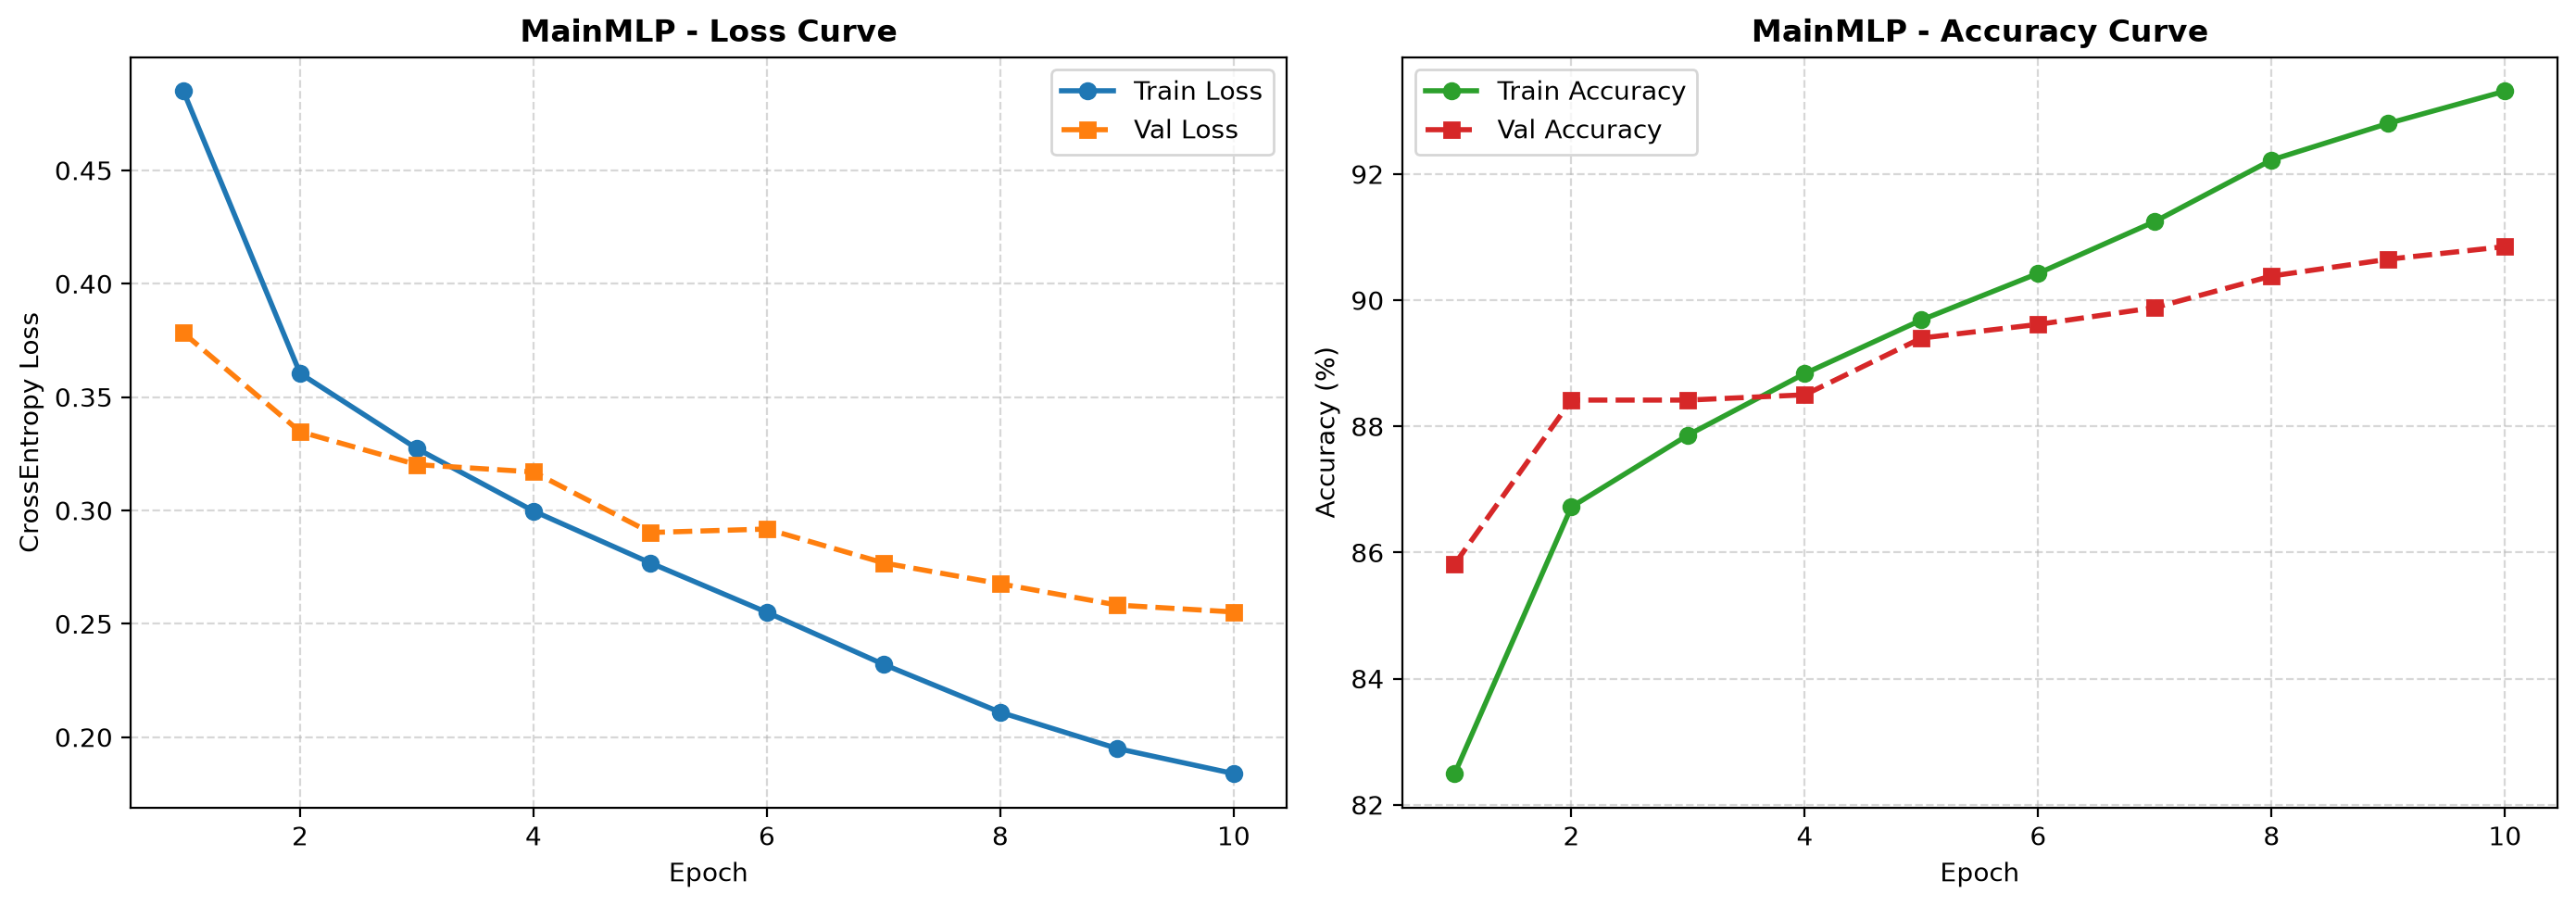

history.csv


,epoch_zero_based,train_loss,train_acc,val_loss,val_acc
0,0,0.484918,82.494444,0.378241,85.816667
1,1,0.360410,86.722222,0.334705,88.416667
2,2,0.327260,87.862963,0.320197,88.416667
3,3,0.299727,88.837037,0.316970,88.500000
4,4,0.276871,89.687037,0.290259,89.400000
5,5,0.255044,90.425926,0.291781,89.616667
6,6,0.232095,91.248148,0.276842,89.883333
7,7,0.210968,92.224074,0.267623,90.383333
8,8,0.195009,92.803704,0.258253,90.650000
9,9,0.183922,93.314815,0.255205,90.850000


Run: C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T165134Z_optimizer_results_081e4a24
optimizer  best_val_acc_fixed  seconds_fixed  best_val_acc_tuned  seconds_tuned
      SGD           85.083333      13.477502           90.800000     100.573697
  RMSprop           90.733333      14.221538           90.566667     132.468404
     Adam           90.933333      15.286586           90.850000     133.978890
fixed_vs_tuned.csv


,optimizer,best_val_acc_fixed,seconds_fixed,best_val_acc_tuned,seconds_tuned
0,SGD,85.083333,13.477502,90.800000,100.573697
1,RMSprop,90.733333,14.221538,90.566667,132.468404
2,Adam,90.933333,15.286586,90.850000,133.978890


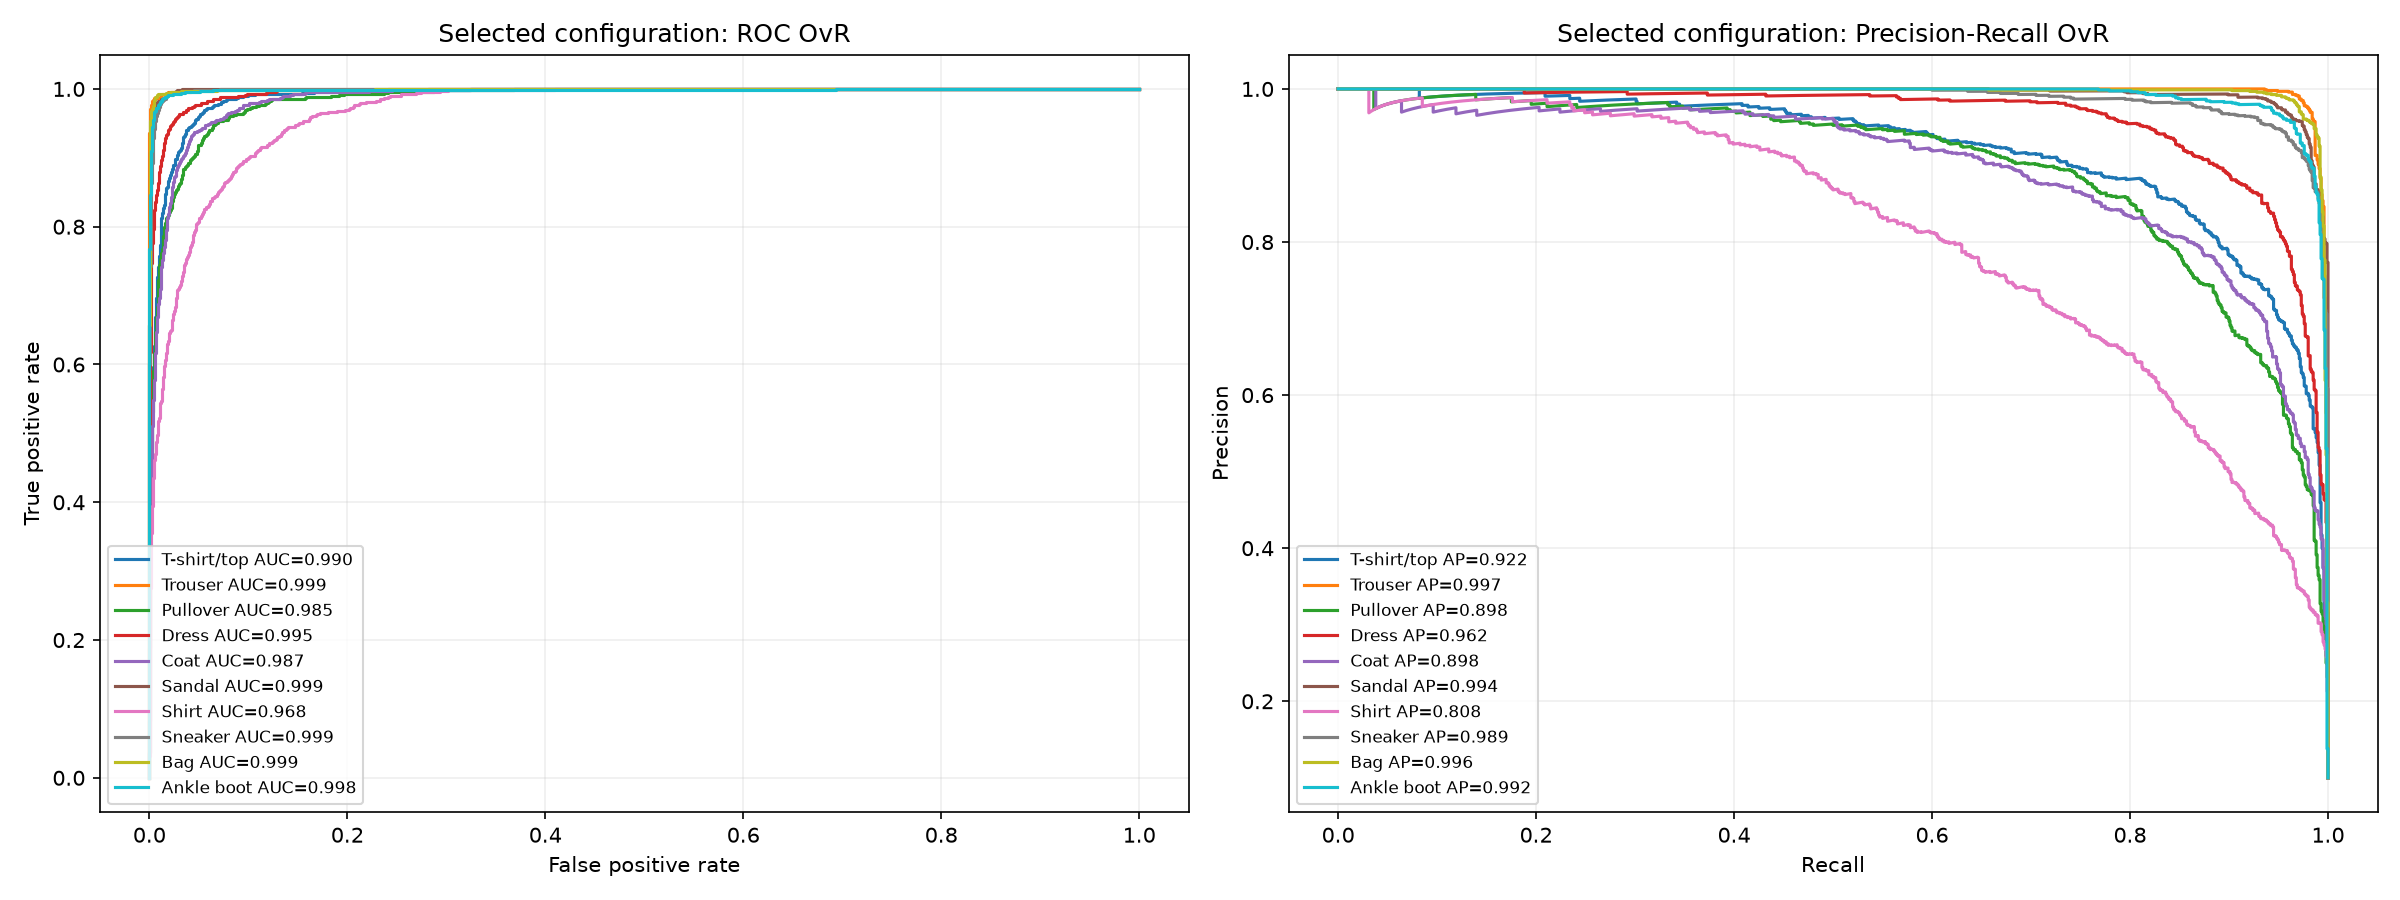

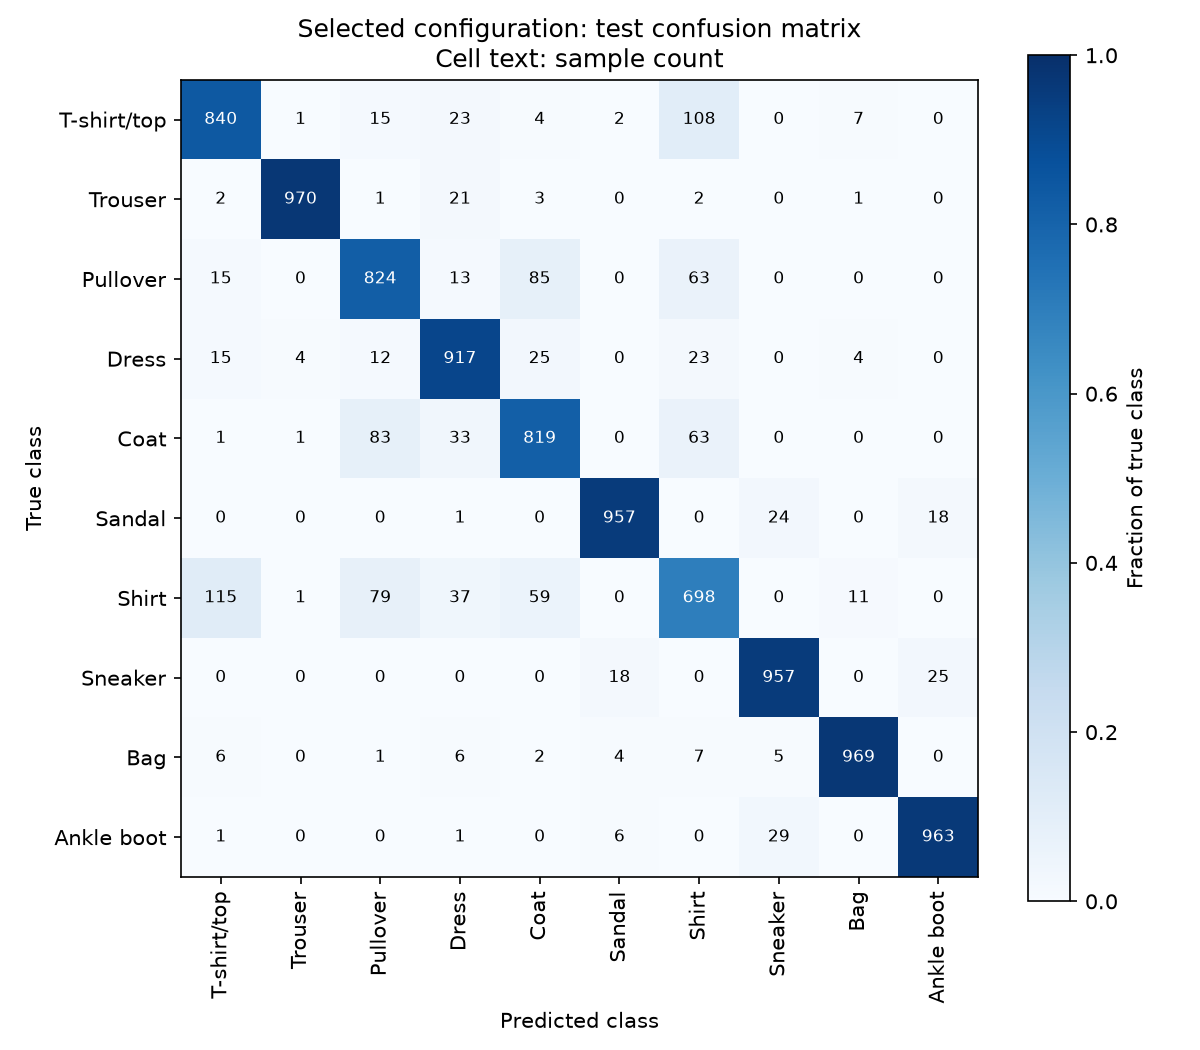

In [32]:
FINAL_RUN = optimizer_stage(CONFIG, 'final', MODE, tuning=TUNING_RUN)
show_images(FINAL_RUN, ['learning_curves.png'])
show_tables(FINAL_RUN, ['history.csv'])
RESULTS_RUN = optimizer_stage(CONFIG, 'optimizer_results', MODE, tuning=TUNING_RUN, fixed=FIXED_RUN, final=FINAL_RUN)
show_tables(RESULTS_RUN, ['fixed_vs_tuned.csv'])
show_images(RESULTS_RUN, ['final_ovr_curves.png', 'final_confusion_matrix.png'])

## 6. Bàn giao artifact
Các biến *_RUN trỏ đến artifact đã dùng/tạo. Cập nhật walkthrough bằng kết quả đã xác minh. Log, config, environment, status và manifest nằm trong mỗi run. Không có phần đọc lại trùng ở cuối; MODE=view dùng chính các cell trên.

## 7. Save / Load the Model
Lưu lại **best validation checkpoint của lượt refit** cùng cấu hình kiến trúc và đường dẫn dữ liệu. Sau đó khởi tạo instance mới, tải state_dict, chuyển sang `eval()` và so sánh xác suất trên tối đa 16 ảnh test trước/sau lưu. Đây là kiểm tra save/load, không dùng để chọn lại hyperparameter.

Cell này thực hiện lưu/tải thật ở cả MODE=view và MODE=train; mỗi lần chạy tạo run `model_save_load` riêng có `best.pt`, `config.json`, `model_architecture.txt`, `roundtrip.json`, `roundtrip_predictions.npz`, log, environment, status và manifest. Khi chuyển máy, mang theo prepared.npz và cập nhật đường dẫn bằng tham số data_path. `LOADED_MODEL` sẵn sàng dùng để suy luận.

Sau khi tải, model được đánh giá trên **toàn bộ tập test**; xuất test_metrics.json, classification_report.json và test_predictions.npz. Lưới hiển thị tối đa 8 mẫu đúng và 8 mẫu sai theo thứ tự index (bổ sung mẫu nếu thiếu), nhãn thật, nhãn dự đoán và xác suất softmax. Màu xanh là đúng, đỏ là sai; lưới minh họa không đại diện cho tỷ lệ lỗi toàn bộ test.

Run: C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T165137Z_model_save_load_f2baeab9
Saved checkpoint: C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T165137Z_model_save_load_f2baeab9\best.pt
Fresh model loaded in eval mode: FashionMLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Save/load verification: {'passed': True, 'samples': 16, 'max_probability_error': 0.0, 'predicted_labels_unchanged': True, 'checkpoint': 'best.pt', 'source_run': 'C:\\Users\\Win 11\\Documents\\Lab DL\\labs\\lab01\\outputs\\runs\\20261022T165113Z_MainMLP_a62528f0'}
Reloaded model, full test split: {'samples': 10000, 'accuracy': 0.8914, 'macro_f1': 0.891219120478717, 'loss': 0.30367913842201233}
loaded_model_test_samples.csv


,test_index,true_label,true_class,predicted_label,predicted_class,probability,correct
0,0,9,Ankle boot,9,Ankle boot,0.993055,True
1,1,2,Pullover,2,Pullover,0.998464,True
2,2,1,Trouser,1,Trouser,1.000000,True
3,3,1,Trouser,1,Trouser,0.999999,True
4,4,6,Shirt,6,Shirt,0.951802,True
5,5,1,Trouser,1,Trouser,0.999993,True
6,6,4,Coat,4,Coat,0.996883,True
7,7,6,Shirt,6,Shirt,0.992665,True
8,12,7,Sneaker,5,Sandal,0.757215,False
9,17,4,Coat,2,Pullover,0.944718,False


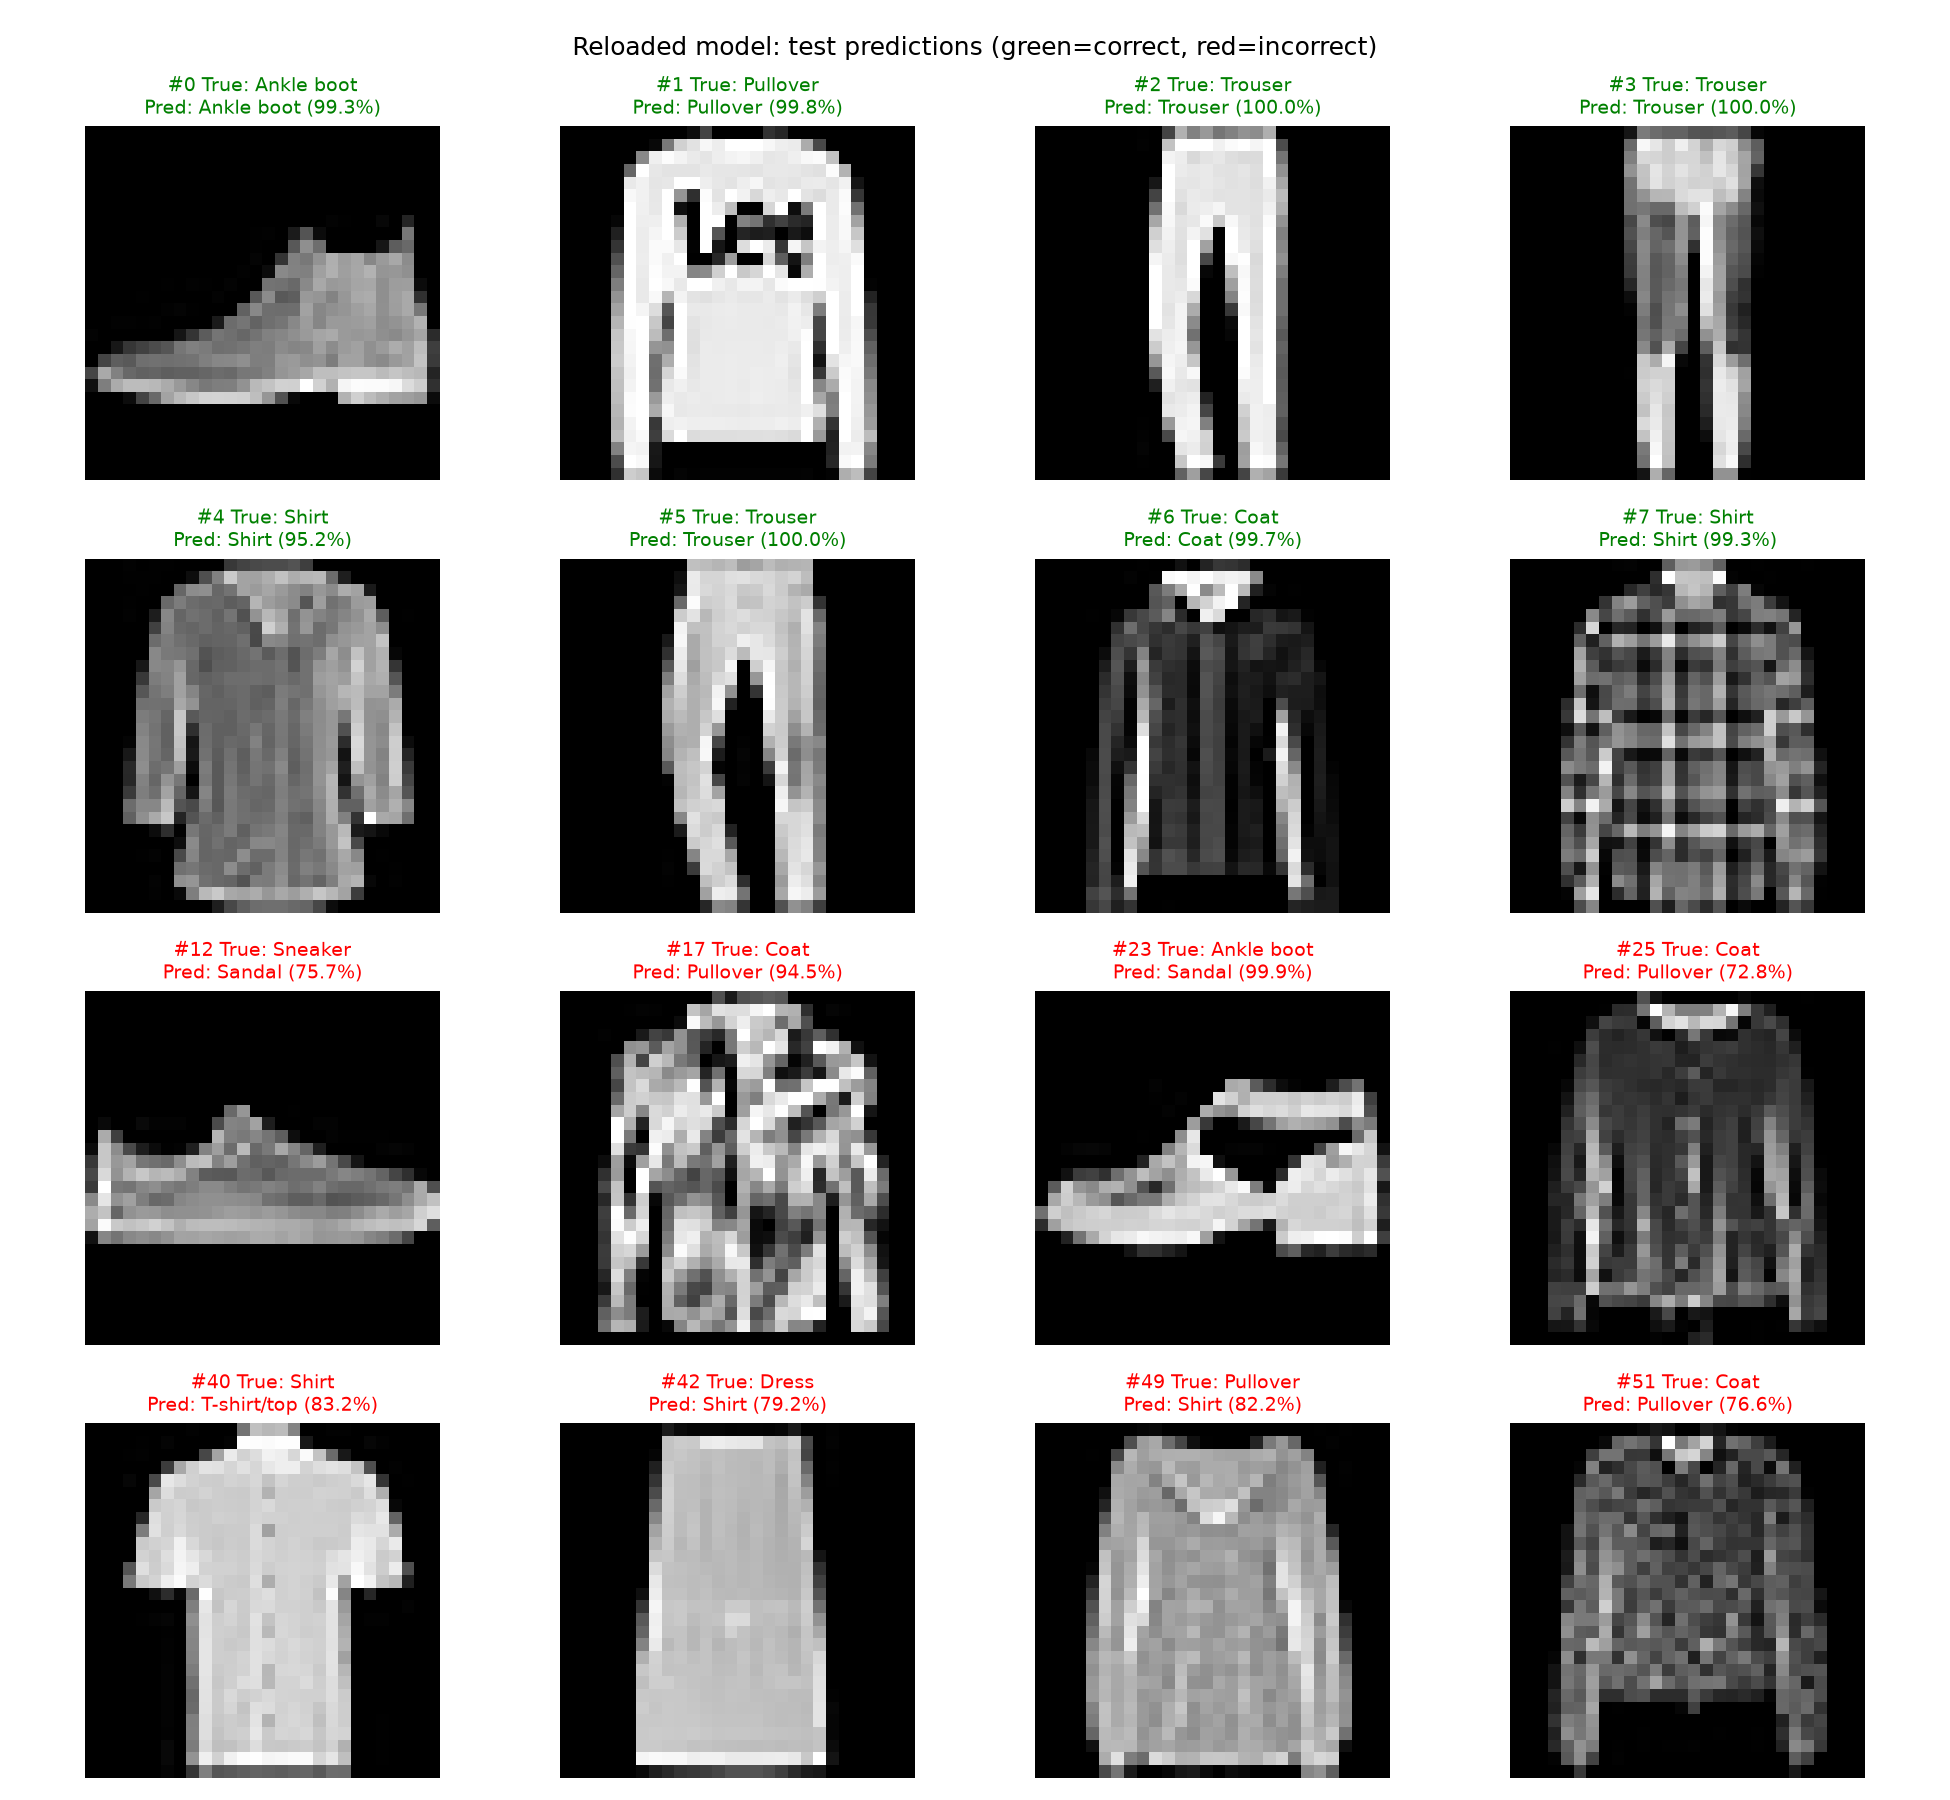

{'samples': 10000,
 'accuracy': 0.8914,
 'macro_f1': 0.891219120478717,
 'loss': 0.30367913842201233}

In [33]:
from src.inference import save_load_model
from src.workflow import saved_run
SAVED_MODEL_RUN, LOADED_MODEL = save_load_model(
    FINAL_RUN, data_path=saved_run(CONFIG, 'preparation') / 'prepared.npz')
show_tables(SAVED_MODEL_RUN, ['loaded_model_test_samples.csv'])
show_images(SAVED_MODEL_RUN, ['loaded_model_test_samples.png'])
import json
display(json.loads((SAVED_MODEL_RUN / 'test_metrics.json').read_text()))